<a href="https://www.kaggle.com/code/makrrc/beating-the-pandas-with-the-polars?scriptVersionId=358790599" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
import numpy as np

from scipy import stats
from scipy.stats import spearmanr

from typing import Dict, List, Optional, Union
import math

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/playground-series-s6e8/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e8/train.csv
/kaggle/input/competitions/playground-series-s6e8/test.csv


In [3]:
import polars as pl
import polars.selectors as cs

In [4]:
def carregar_bases():
    for dirname, _, filenames in os.walk('/kaggle/input'):
        for filename in filenames:
            print(os.path.join(dirname, filename))
            if filename == 'train.csv':
                train = pl.scan_csv( os.path.join(dirname, filename) )
            elif filename == 'test.csv':
                test = pl.scan_csv( os.path.join(dirname, filename) )
                
    return train, test

In [5]:
[train, test] = carregar_bases()

/kaggle/input/competitions/playground-series-s6e8/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e8/train.csv
/kaggle/input/competitions/playground-series-s6e8/test.csv


In [6]:
df_train = train.collect()
df_test = test.collect()

In [7]:
def unique_values_by_column(dataframe, column):
    if df_train[column].dtype == pl.Int64 or df_train[column].dtype == pl.Float64:
        return dataframe[column].unique().count()

In [8]:
def mean_values_by_column(dataframe, column):
    if df_train[column].dtype == pl.Int64 or df_train[column].dtype == pl.Float64:
        return dataframe[column].mean()

In [9]:
def max_values_by_column(dataframe, column):
    if df_train[column].dtype == pl.Int64 or df_train[column].dtype == pl.Float64:
        return dataframe[column].max()

In [10]:
def min_values_by_column(dataframe, column):
    if df_train[column].dtype == pl.Int64 or df_train[column].dtype == pl.Float64:
        return dataframe[column].min()

In [11]:
min = pl.DataFrame({})
type(min)

polars.dataframe.frame.DataFrame

In [12]:
# 1ºversão do profile

# unique = {}
# mean = {}
# max = {}
# min = {}

# for column in df_train.columns:
#     mean[column] = mean_values_by_column(df_train, column)
#     unique[column] = unique_values_by_column(df_train, column)
#     max[column] = max_values_by_column(df_train, column)
#     min[column] = min_values_by_column(df_train, column)

# unique = pl.DataFrame(unique)
# mean = pl.DataFrame(mean)
# max = pl.DataFrame(max)
# min = pl.DataFrame(min)

In [13]:
def plot_target_hue(df, column, target_column):
    plt.figure(figsize=(18,6))
    sns.countplot(data=df, x=column, hue=target_column)
    plt.xticks(rotation=90)
    plt.title(f'{column} vs {target_column}')
    plt.show()

In [14]:
def get_bool1(dataset, column, yes, no):
    temp = dataset[column].replace({yes:1,no:0})
    temp = temp
    return temp

In [15]:
def get_dummies1(dataset, column):
    result = ''
    for elemento in column:
        print(elemento)
        temp = pd.get_dummies(dataset[elemento], drop_first=True)
        dataset = pd.concat([dataset, temp], axis=1)
    return dataset  

In [16]:
from sklearn.preprocessing import OrdinalEncoder

oe = OrdinalEncoder()
def CodificarOrdinalEncoder(dataset, column, encoder):
    """
    Codifica uma coluna categórica usando OrdinalEncoder e
    adiciona uma nova coluna codificada ao DataFrame.
    """
    # O erro estava aqui: precisamos passar [[column]] para garantir 2D
    encoder.fit(dataset[[column]])  
    dataset['oe_' + column] = encoder.transform(dataset[[column]])
    return dataset

In [17]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

def CodificarLabelEncode(Dataset, columns, LabelEncoder):
    LabelEncoder.fit(Dataset[columns])
    Dataset['le_'+columns] = LabelEncoder.transform(Dataset[columns])
    return Dataset

In [18]:
def roac_au(X,y, model ):
    from sklearn.metrics import roc_auc_score
    return roc_auc_score(y, model.predict_proba(X)[:, 1])

In [19]:
def analisar_cardinalidade(df: pl.DataFrame) -> pl.DataFrame:
    """Retorna DataFrame com cardinalidade e métricas por coluna"""
    total_linhas = df.height
    
    resultado = []
    for col in df.columns:
        n_unique = df[col].n_unique()
        n_nulos = df[col].null_count()
        dtype = df[col].dtype
        
        # Classificação
        #Percentual de valores únicos
        pct_unique = n_unique / total_linhas * 100
        pct_nulos = n_nulos / total_linhas * 100
        
        if n_unique == 1:
            tipo = "🔴 Constante"
        elif n_unique <= 10:
            tipo = "🟠 Baixa (prov. categórica)"
        elif pct_unique <= 5:
            tipo = "🟡 Média-baixa"
        elif pct_unique <= 50:
            tipo = "🟢 Média"
        else:
            tipo = "🔵 Alta (prov. ID/contínua)"
        
        resultado.append({
            "coluna": col,
            "n_unique": n_unique,
            "n_nulos": n_nulos,
            "pct_nulos": round(pct_nulos, 2),
            "pct_unique": round(pct_unique, 2),
            "dtype": str(dtype),
            "classificacao": tipo
        })
    
    return (
        pl.DataFrame(resultado)
        .sort("n_unique")
    )


# Uso



In [20]:
def detectar_registros_vazios(
    df: pl.DataFrame,
    id_col: str = "id",
    target_col: str = None,
) -> pl.DataFrame:
    """
    Identifica linhas onde apenas 'id' e a variável alvo estão preenchidas,
    e todas as demais colunas estão vazias.

    O critério de "vazio" é aplicado conforme o tipo da coluna:
    - String  -> null, "", " ", "nan", "NaN", "NA", "None"
    - Numérico -> null, NaN
    - Outros  -> null
    """
    colunas_ignorar = [id_col]
    if target_col:
        colunas_ignorar.append(target_col)

    colunas_features = [c for c in df.columns if c not in colunas_ignorar]

    if not colunas_features:
        raise ValueError("Nenhuma coluna de feature encontrada para analisar!")

    print(f"🔍 Analisando {df.height} linhas e {len(colunas_features)} colunas de features...")

    expressoes_vazias = []

    for col in colunas_features:
        dtype = df[col].dtype

        # Critério base: sempre considera null como vazio
        expr_vazia = pl.col(col).is_null()

        # Para strings, adiciona strings "vazias" comuns
        if dtype == pl.Utf8:
            expr_vazia = expr_vazia | pl.col(col).is_in(["", " ", "nan", "NaN", "NA", "None", "null"])
        # Para floats, adiciona NaN
        elif dtype in [pl.Float32, pl.Float64]:
            expr_vazia = expr_vazia | pl.col(col).is_nan()

        expressoes_vazias.append(expr_vazia)

    # Combina todas as condições com AND (todas as features vazias)
    expressao_todas_vazias = expressoes_vazias[0]
    for expr in expressoes_vazias[1:]:
        expressao_todas_vazias = expressao_todas_vazias & expr

    # Filtra as linhas suspeitas
    registros_suspeitos = df.filter(expressao_todas_vazias)

    if registros_suspeitos.height > 0:
        print(f"⚠️  Encontrados {registros_suspeitos.height} registros suspeitos!")
    else:
        print("✅ Nenhum registro com apenas id/alvo preenchidos encontrado.")

    return registros_suspeitos

In [21]:
def encontrar_linhas_todas_nulas(
    df: pl.DataFrame,
    colunas: list[str]
) -> pl.DataFrame:
    """
    Retorna as linhas onde TODAS as colunas especificadas estão null.
    
    Parâmetros
    ----------
    df : pl.DataFrame
        DataFrame a ser analisado.
    colunas : list[str]
        Lista de nomes das colunas que devem estar todas null.
    
    Retorno
    -------
    pl.DataFrame
        Linhas onde todas as colunas listadas estão null.
    """
    # Constrói expressão: todas as colunas null
    expr = pl.col(colunas[0]).is_null()
    for col in colunas[1:]:
        expr = expr & pl.col(col).is_null()
    
    # Filtra
    resultado = df.filter(expr)
    
    print(f"🔍 Linhas com todas as {len(colunas)} colunas null: {resultado.height}")
    print(f"   Percentual do total: {(resultado.height / df.height * 100):.2f}%")
    
    return resultado

In [22]:
def remove_colunas_constantes(
    df: pl.DataFrame,
    remover_com_nulos: bool = False,
    retornar_removidas: bool = False
) -> Union[pl.DataFrame, tuple]:
    """
    Remove colunas constantes do DataFrame.

    Parâmetros:
    -----------
    df : pl.DataFrame
    remover_com_nulos : bool, default=False
        Se True, remove também colunas que têm 1 valor + nulos.
        Se False (padrão), MANTÉM colunas com nulos, pois os nulos
        podem ser informativos (dado faltante ≠ dado constante).
    retornar_removidas : bool, default=False
    
    Retorna:
    --------
    pl.DataFrame sem colunas constantes (e opcionalmente lista de removidas)
    """
    
    colunas_removidas: List[str] = []
    colunas_manter: List[str] = []
    
    for col in df.columns:
        n_unique = df[col].drop_nulls().n_unique()
        n_nulos = df[col].null_count()
        
        # Caso 1: só nulos → remove sempre
        if n_unique == 0:
            colunas_removidas.append(col)
            print(f"🔴 '{col}' → REMOVIDA (só tem nulos)")
        
        # Caso 2: 1 valor, sem nulos → remove
        elif n_unique == 1 and n_nulos == 0:
            valor = df[col].drop_nulls()[0]
            colunas_removidas.append(col)
            print(f"🔴 '{col}' → REMOVIDA (constante = '{valor}')")
        
        # Caso 3: 1 valor + nulos → depende do parâmetro
        elif n_unique == 1 and n_nulos > 0:
            if remover_com_nulos:
                valor = df[col].drop_nulls()[0]
                colunas_removidas.append(col)
                print(f"🔴 '{col}' → REMOVIDA (constante = '{valor}' + {n_nulos} nulos)")
            else:
                colunas_manter.append(col)
                print(f"🟢 '{col}' → MANTIDA (1 valor + {n_nulos} nulos — podem ser informativos)")
        
        # Caso 4: múltiplos valores → mantém
        else:
            colunas_manter.append(col)
    
    df_limpo = df.select(colunas_manter)
    
    print(f"\n📊 Resultado: {len(colunas_removidas)} removidas | {len(colunas_manter)} mantidas")
    
    if retornar_removidas:
        return df_limpo, colunas_removidas
    
    return df_limpo

In [23]:
def boxplot_todas_colunas(df: pl.DataFrame, colunas: list[str] = None) -> None:
    """
    Gera um único boxplot com todas as colunas numéricas lado a lado.
    Útil para comparar a escala e dispersão entre variáveis.
    """
    if colunas is None:
        tipos_numericos = [pl.Int8, pl.Int16, pl.Int32, pl.Int64,
                           pl.Float32, pl.Float64]
        colunas = [c for c in df.columns if df[c].dtype in tipos_numericos]

    # Converte para pandas só para o seaborn (mais simples de plotar)
    df_pd = df.select(colunas).to_pandas()

    plt.figure(figsize=(16, 6))
    sns.boxplot(data=df_pd, orient="h", palette="Set2",
                flierprops=dict(marker="o", markerfacecolor="red",
                                markersize=4, linestyle="none"))
    plt.title("Distribuição e Outliers por Coluna", fontsize=14, weight="bold")
    plt.xlabel("Valor")
    plt.tight_layout()
    plt.show()

In [24]:
df_train['addicted_label'].value_counts()

addicted_label,count
i64,u32
1,490474
0,200895


In [25]:
cardinalidade = analisar_cardinalidade(df_train)
cardinalidade

coluna,n_unique,n_nulos,pct_nulos,pct_unique,dtype,classificacao
str,i64,i64,f64,f64,str,str
"""addicted_label""",2,0,0.0,0.0,"""Int64""","""🟠 Baixa (prov. categórica)"""
"""academic_work_impact""",3,44224,6.4,0.0,"""String""","""🟠 Baixa (prov. categórica)"""
"""gender""",4,29034,4.2,0.0,"""String""","""🟠 Baixa (prov. categórica)"""
"""stress_level""",4,55148,7.98,0.0,"""String""","""🟠 Baixa (prov. categórica)"""
"""age""",19,28929,4.18,0.0,"""Float64""","""🟡 Média-baixa"""
…,…,…,…,…,…,…
"""work_study_hours""",601,51518,7.45,0.09,"""Float64""","""🟡 Média-baixa"""
"""social_media_hours""",722,133995,19.38,0.1,"""Float64""","""🟡 Média-baixa"""
"""daily_screen_time_hours""",1390,95854,13.86,0.2,"""Float64""","""🟡 Média-baixa"""


In [26]:
cardinalidade['classificacao']

classificacao
str
"""🟠 Baixa (prov. categórica)"""
"""🟠 Baixa (prov. categórica)"""
"""🟠 Baixa (prov. categórica)"""
"""🟠 Baixa (prov. categórica)"""
"""🟡 Média-baixa"""
…
"""🟡 Média-baixa"""
"""🟡 Média-baixa"""
"""🟡 Média-baixa"""


Analisar as linhas com média cardinalidade. E, a partir das métricas, entender se há nulos, duplicados e os tipos de dados.

In [27]:
type(cardinalidade)

polars.dataframe.frame.DataFrame

.select('social_media_hours')

In [28]:
cardinalidade.filter(pl.col('classificacao') == "🟡 Média-baixa").sort(['n_nulos'], descending=True)

coluna,n_unique,n_nulos,pct_nulos,pct_unique,dtype,classificacao
str,i64,i64,f64,f64,str,str
"""social_media_hours""",722,133995,19.38,0.1,"""Float64""","""🟡 Média-baixa"""
"""gaming_hours""",402,126821,18.34,0.06,"""Float64""","""🟡 Média-baixa"""
"""weekend_screen_time""",1438,112063,16.21,0.21,"""Float64""","""🟡 Média-baixa"""
"""daily_screen_time_hours""",1390,95854,13.86,0.2,"""Float64""","""🟡 Média-baixa"""
"""app_opens_per_day""",167,80710,11.67,0.02,"""Float64""","""🟡 Média-baixa"""
"""notifications_per_day""",232,67584,9.78,0.03,"""Float64""","""🟡 Média-baixa"""
"""work_study_hours""",601,51518,7.45,0.09,"""Float64""","""🟡 Média-baixa"""
"""sleep_hours""",452,44480,6.43,0.07,"""Float64""","""🟡 Média-baixa"""
"""age""",19,28929,4.18,0.0,"""Float64""","""🟡 Média-baixa"""


In [29]:
# colunas_alvo = [
#     "social_media_hours",
#     "gaming_hours",
#     "weekend_screen_time",
#     "daily_screen_time_hours",
#     "app_opens_per_day",
#     "notifications_per_day",
#     "work_study_hours",
#     "sleep_hours",
#     "age"
# ]

# colunas_alvo

In [30]:
colunas_alvo = cardinalidade.filter(pl.col('classificacao') == "🟡 Média-baixa").sort(['n_nulos'], descending=True)['coluna'].to_list()
colunas_alvo

['social_media_hours',
 'gaming_hours',
 'weekend_screen_time',
 'daily_screen_time_hours',
 'app_opens_per_day',
 'notifications_per_day',
 'work_study_hours',
 'sleep_hours',
 'age']

In [31]:
encontrar_linhas_todas_nulas(df_train, colunas_alvo)

🔍 Linhas com todas as 9 colunas null: 2
   Percentual do total: 0.00%


id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,i64
282772,null,null,null,null,null,null,null,null,null,"""Other""","""Low""","""Yes""",1
617575,null,null,null,null,null,null,null,null,null,"""Other""","""High""",null,0


In [32]:
encontrar_linhas_todas_nulas(df_test, colunas_alvo)

🔍 Linhas com todas as 9 colunas null: 0
   Percentual do total: 0.00%


id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str


Muito bom. Temos dois registros que talvez não tenha muita informação para o nosso modelo. E pode atralhar na inferência. Próximo passo remover estas linhas.

In [33]:
detectar_registros_vazios(df_train, "id","addicted_label")

🔍 Analisando 691369 linhas e 12 colunas de features...
✅ Nenhum registro com apenas id/alvo preenchidos encontrado.


id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,i64


In [34]:
detectar_registros_vazios(df_test, "id","addicted_label")

🔍 Analisando 296302 linhas e 12 colunas de features...
✅ Nenhum registro com apenas id/alvo preenchidos encontrado.


id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str


In [38]:
df_train = remove_colunas_constantes(df_train)
df_train


📊 Resultado: 0 removidas | 14 mantidas


id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,i64
0,24.0,null,1.83,1.59,2.11,7.46,122.0,38.0,8.63,"""Male""","""Medium""","""No""",1
1,19.0,5.97,1.08,null,3.03,8.22,76.0,19.0,null,"""Female""","""Medium""","""No""",0
2,18.0,5.09,null,null,null,6.25,134.0,60.0,7.47,"""Female""","""Low""","""Yes""",0
3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,"""Other""","""Low""",null,1
4,26.0,11.2,1.87,2.81,1.95,5.25,null,null,13.39,"""Female""","""Medium""","""No""",1
…,…,…,…,…,…,…,…,…,…,…,…,…,…
691364,22.0,10.78,3.25,1.57,1.65,7.71,86.0,94.0,12.89,"""Male""",null,"""No""",1
691365,20.0,3.45,1.86,0.89,0.3,6.59,221.0,42.0,8.47,"""Female""","""High""","""No""",1
691366,null,null,null,null,2.06,6.16,null,86.0,7.79,"""Other""","""Medium""","""No""",1


In [39]:
df_test = remove_colunas_constantes(df_test)
df_test


📊 Resultado: 0 removidas | 13 mantidas


id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str
691369,30.0,9.34,null,0.77,4.09,7.15,153.0,16.0,null,"""Other""","""Medium""","""Yes"""
691370,null,null,1.91,null,1.2,8.67,239.0,148.0,10.68,"""Female""","""High""","""No"""
691371,26.0,8.48,3.64,null,3.39,7.47,106.0,123.0,null,"""Male""",null,"""No"""
691372,20.0,8.37,2.99,1.69,2.53,5.45,178.0,55.0,9.88,"""Male""","""High""","""Yes"""
691373,25.0,8.25,4.02,1.21,2.32,8.46,63.0,86.0,10.72,"""Male""","""Low""","""No"""
…,…,…,…,…,…,…,…,…,…,…,…,…
987666,25.0,11.76,5.15,1.94,2.75,8.24,237.0,127.0,14.1,"""Male""",null,null
987667,28.0,7.67,2.7,1.55,2.95,5.54,187.0,121.0,8.25,"""Male""","""Low""","""Yes"""
987668,33.0,5.27,1.84,0.2,2.44,8.29,96.0,73.0,6.57,"""Female""","""High""","""No"""



=== Dados que serão plotados ===
Min: 1.0000
Max: 1.0000
NaNs: 90
[[ 1. nan nan nan nan nan nan nan nan nan]
 [nan  1. nan nan nan nan nan nan nan nan]
 [nan nan  1. nan nan nan nan nan nan nan]
 [nan nan nan  1. nan nan nan nan nan nan]
 [nan nan nan nan  1. nan nan nan nan nan]
 [nan nan nan nan nan  1. nan nan nan nan]
 [nan nan nan nan nan nan  1. nan nan nan]
 [nan nan nan nan nan nan nan  1. nan nan]
 [nan nan nan nan nan nan nan nan  1. nan]
 [nan nan nan nan nan nan nan nan nan  1.]]


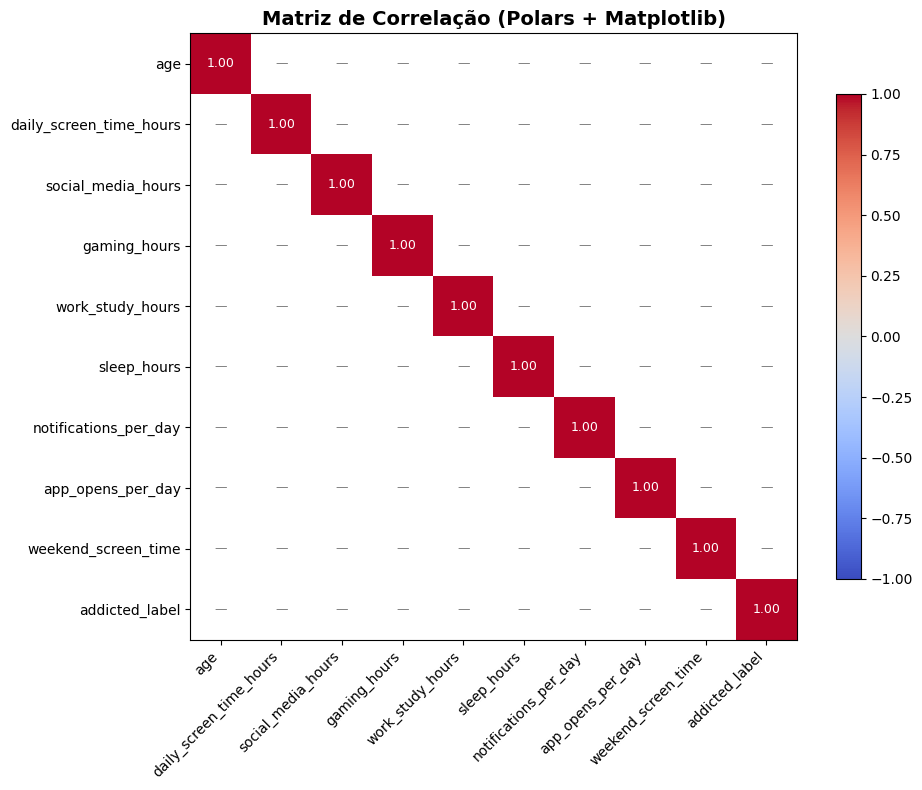

In [41]:
def plot_corr(df: pl.DataFrame, drop_id: bool = True):
    # 1. Seleciona colunas numéricas
    df_numeric = df.select(cs.numeric())
    
    if drop_id and "id" in df_numeric.columns:
        df_numeric = df_numeric.drop("id")
    
    # 2. Remove colunas constantes
    colunas_constantes = [
        col for col in df_numeric.columns
        if df_numeric[col].std() is None or df_numeric[col].std() == 0
    ]
    if colunas_constantes:
        print(f"⚠️ Colunas removidas (variância zero): {colunas_constantes}")
        df_numeric = df_numeric.drop(colunas_constantes)
    
    if df_numeric.width < 2:
        print("❌ Menos de 2 colunas válidas.")
        return
    
    # 3. Correlação 100% Polars
    corr_matrix = df_numeric.corr()
    colunas = corr_matrix.columns
    
    # 4. CONVERSÃO CORRETA: preenche None com NaN ANTES de virar numpy
    #    e mantém os valores válidos intactos
    dados = np.zeros((len(colunas), len(colunas)))
    for i, col in enumerate(colunas):
        valores = corr_matrix[col].cast(pl.Float64).fill_null(float("nan")).to_numpy()
        dados[i, :] = valores
    
    # 5. Força diagonal = 1
    np.fill_diagonal(dados, 1.0)
    
    # 6. Mostra o que vai plotar (debug)
    print("\n=== Dados que serão plotados ===")
    print(f"Min: {np.nanmin(dados):.4f}")
    print(f"Max: {np.nanmax(dados):.4f}")
    print(f"NaNs: {np.isnan(dados).sum()}")
    print(dados)
    
    # 7. Plot
    fig, ax = plt.subplots(figsize=(10, 8))
    im = ax.imshow(dados, cmap="coolwarm", vmin=-1, vmax=1)
    
    ax.set_xticks(range(len(colunas)))
    ax.set_yticks(range(len(colunas)))
    ax.set_xticklabels(colunas, rotation=45, ha="right")
    ax.set_yticklabels(colunas)
    
    for i in range(len(colunas)):
        for j in range(len(colunas)):
            val = dados[i, j]
            if np.isnan(val):
                text = "—"
                color = "gray"
            else:
                text = f"{val:.2f}"
                color = "white" if abs(val) > 0.5 else "black"
            ax.text(j, i, text, ha="center", va="center",
                    color=color, fontsize=9)
    
    fig.colorbar(im, ax=ax, shrink=0.8)
    plt.title("Matriz de Correlação (Polars + Matplotlib)",
              fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()
plot_corr(df_train)  

In [42]:
df_train

id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,i64
0,24.0,null,1.83,1.59,2.11,7.46,122.0,38.0,8.63,"""Male""","""Medium""","""No""",1
1,19.0,5.97,1.08,null,3.03,8.22,76.0,19.0,null,"""Female""","""Medium""","""No""",0
2,18.0,5.09,null,null,null,6.25,134.0,60.0,7.47,"""Female""","""Low""","""Yes""",0
3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,"""Other""","""Low""",null,1
4,26.0,11.2,1.87,2.81,1.95,5.25,null,null,13.39,"""Female""","""Medium""","""No""",1
…,…,…,…,…,…,…,…,…,…,…,…,…,…
691364,22.0,10.78,3.25,1.57,1.65,7.71,86.0,94.0,12.89,"""Male""",null,"""No""",1
691365,20.0,3.45,1.86,0.89,0.3,6.59,221.0,42.0,8.47,"""Female""","""High""","""No""",1
691366,null,null,null,null,2.06,6.16,null,86.0,7.79,"""Other""","""Medium""","""No""",1


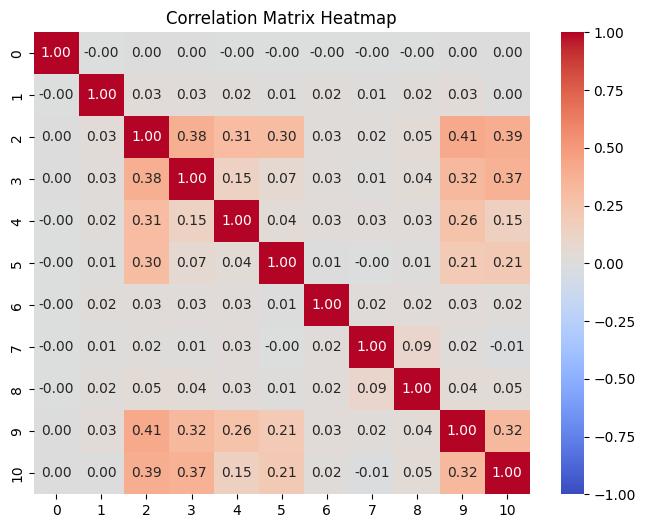

In [43]:
# 3. Plot using Seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(df_train.select(cs.numeric()).fill_null(0).corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Matrix Heatmap")
plt.show()

In [45]:
df_num = df_train.select(cs.numeric())

# Verifica as correlações mais fortes (mesmo que baixas)
corr = df_num.corr()
print("\n=== TOP 10 CORRELAÇÕES MAIS FORTES ===")
correlacoes = []
for col in corr.columns:
    for j in range(len(corr.columns)):
        val = corr[col][j]
        col2 = corr.columns[j]
        if col < col2 and val is not None:
            correlacoes.append((col, col2, val))

correlacoes.sort(key=lambda x: abs(x[2]), reverse=True)
for c1, c2, v in correlacoes[:10]:
    print(f"  {c1:20s} × {c2:20s} = {v:+.4f}")



=== TOP 10 CORRELAÇÕES MAIS FORTES ===
  id                   × social_media_hours   = +nan
  id                   × work_study_hours     = +nan
  id                   × sleep_hours          = +nan
  id                   × notifications_per_day = +nan
  id                   × weekend_screen_time  = +nan
  age                  × id                   = +nan
  age                  × daily_screen_time_hours = +nan
  age                  × social_media_hours   = +nan
  age                  × gaming_hours         = +nan
  age                  × work_study_hours     = +nan


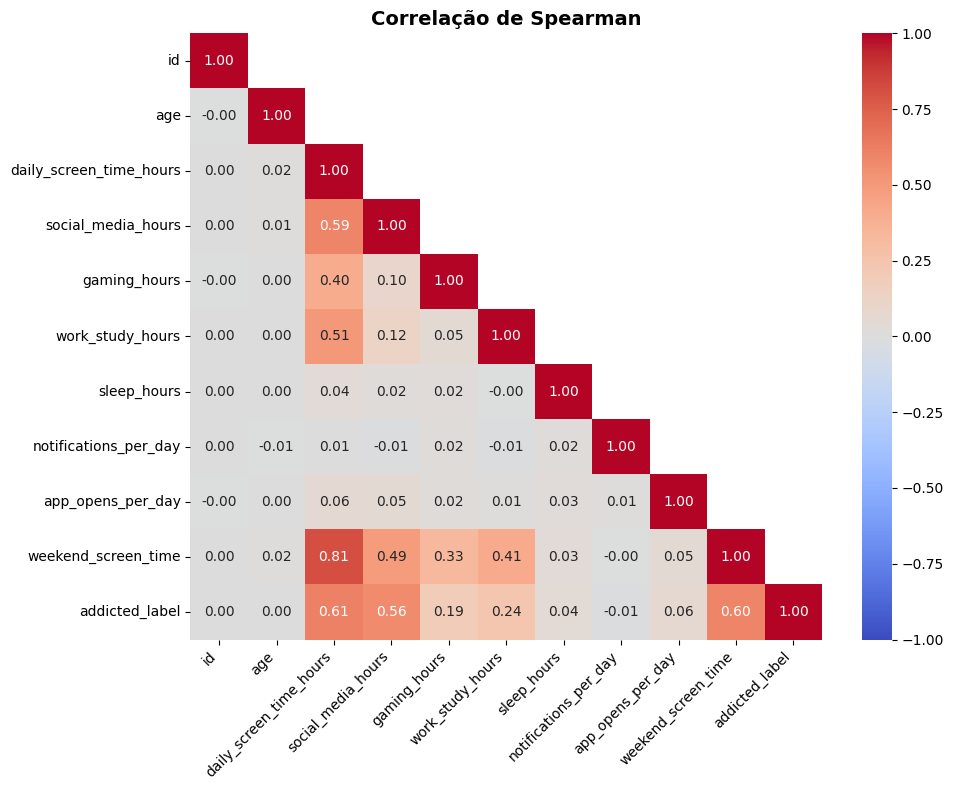

array([[ 1.00000000e+00, -1.11154947e-03,  1.24217130e-03,
         2.87642235e-03, -2.10546568e-03,  1.45216685e-03,
         3.25501966e-04,  1.37825602e-04, -1.34867869e-04,
         1.34752470e-03,  1.43514664e-03],
       [-1.11154947e-03,  1.00000000e+00,  1.50651059e-02,
         8.50222592e-03,  1.96730134e-03,  1.50778721e-03,
         2.32984458e-03, -6.09694905e-03,  5.20506758e-04,
         1.50062577e-02,  3.84035484e-03],
       [ 1.24217130e-03,  1.50651059e-02,  1.00000000e+00,
         5.94056445e-01,  4.04011615e-01,  5.07005123e-01,
         3.57768947e-02,  6.82308989e-03,  5.81639759e-02,
         8.12514065e-01,  6.12585186e-01],
       [ 2.87642235e-03,  8.50222592e-03,  5.94056445e-01,
         1.00000000e+00,  1.00145270e-01,  1.24797433e-01,
         2.00644900e-02, -1.30840745e-02,  5.08385569e-02,
         4.89141380e-01,  5.64135961e-01],
       [-2.10546568e-03,  1.96730134e-03,  4.04011615e-01,
         1.00145270e-01,  1.00000000e+00,  5.44179463e-02,
  

In [46]:
def spearman_corr_matrix(df: pl.DataFrame):
    """Calcula correlação de Spearman (captura relações não-lineares)"""
    df_num = df.select(cs.numeric()).drop_nulls()
    colunas = df_num.columns
    n = len(colunas)
    matriz = np.zeros((n, n))
    
    for i, c1 in enumerate(colunas):
        for j, c2 in enumerate(colunas):
            if i == j:
                matriz[i, j] = 1.0
            elif i < j:
                r, _ = spearmanr(df_num[c1].to_numpy(), df_num[c2].to_numpy())
                matriz[i, j] = r
                matriz[j, i] = r
    
    # Plot
    mask = np.triu(np.ones_like(matriz, dtype=bool), k=1)
    plt.figure(figsize=(10, 8))
    sns.heatmap(matriz, mask=mask, annot=True, fmt=".2f",
                xticklabels=colunas, yticklabels=colunas,
                cmap="coolwarm", center=0, vmin=-1, vmax=1)
    plt.title("Correlação de Spearman", fontsize=14, fontweight="bold")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
    return matriz


spearman_corr_matrix(df_train)

In [47]:
def plot_barplot(df: pl.DataFrame,x,y):
    sns.barplot(data=df, x=x, y=y)

# plot_barplot( df_train,'health_condition','sleep_duration' )

In [48]:

def profile(df: pl.DataFrame) -> pl.DataFrame:
    # Seleciona colunas numéricas automaticamente
    colunas_numericas = df.select(cs.numeric()).columns

    if not colunas_numericas:
        return pl.DataFrame()

    stats = []
    for col in colunas_numericas:
        serie = df[col]

        # Pega a primeira moda (ou None se não houver)
        moda = serie.mode().item(0) if serie.mode().len() > 0 else None

        stats.append({
            "coluna":      col,
            "tipo":        str(serie.dtype),
            "nulos":       serie.null_count(),
            "unicos":      serie.n_unique(),
            "moda":        moda,
            "média":       serie.mean(),
            "std":         serie.std(),
            "mínimo":      serie.min(),
            "Q1":          serie.quantile(0.25, interpolation="nearest"),
            "mediana":     serie.median(),
            "Q3":          serie.quantile(0.75, interpolation="nearest"),
            "máximo":      serie.max(),
        })

    return pl.DataFrame(stats)

profile( df_train )

coluna,tipo,nulos,unicos,moda,média,std,mínimo,Q1,mediana,Q3,máximo
str,str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""id""","""Int64""",0,691369,440231.0,345684.0,199581.183467,0.0,172842.0,345684.0,518526.0,691368.0
"""age""","""Float64""",28929,19,31.0,26.615408,5.153162,18.0,22.0,27.0,31.0,35.0
"""daily_screen_time_hours""","""Float64""",95854,1390,null,7.640865,2.721446,0.5,5.48,7.77,9.84,15.0
"""social_media_hours""","""Float64""",133995,722,null,2.471038,1.316137,0.0,1.45,2.31,3.37,8.0
"""gaming_hours""","""Float64""",126821,402,null,1.459265,0.934552,0.0,0.7,1.33,2.09,4.0
…,…,…,…,…,…,…,…,…,…,…,…
"""sleep_hours""","""Float64""",44480,452,null,6.804334,1.234512,4.5,5.78,6.8,7.87,9.0
"""notifications_per_day""","""Float64""",67584,232,null,145.8949,65.917556,20.0,93.0,150.0,204.0,250.0
"""app_opens_per_day""","""Float64""",80710,167,null,102.636781,48.09397,15.0,64.0,104.0,145.0,180.0


In [49]:
profile( df_test )

coluna,tipo,nulos,unicos,moda,média,std,mínimo,Q1,mediana,Q3,máximo
str,str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""id""","""Int64""",0,296302,802117.0,839519.5,85535.164068,691369.0,765444.0,839519.5,913595.0,987670.0
"""age""","""Float64""",17138,19,31.0,26.608689,5.153359,18.0,22.0,27.0,31.0,35.0
"""daily_screen_time_hours""","""Float64""",32788,1350,null,7.640771,2.725921,0.5,5.46,7.77,9.85,15.0
"""social_media_hours""","""Float64""",47397,704,null,2.471224,1.318143,0.0,1.45,2.32,3.37,7.85
"""gaming_hours""","""Float64""",59420,402,null,1.457668,0.934727,0.0,0.69,1.33,2.09,4.0
"""work_study_hours""","""Float64""",27777,602,null,2.365962,1.257023,0.0,1.36,2.2,3.2,6.0
"""sleep_hours""","""Float64""",22455,452,null,6.801704,1.23608,4.5,5.77,6.8,7.87,9.0
"""notifications_per_day""","""Float64""",34221,232,null,145.748066,66.014554,20.0,93.0,150.0,204.0,250.0
"""app_opens_per_day""","""Float64""",25705,167,null,102.656216,48.1862,15.0,63.0,104.0,145.0,180.0


In [50]:
def plot_countplot(df: pl.DataFrame, x: str | None = None):
    """
    Plota countplot de uma coluna específica ou de todas as colunas categóricas.
    
    Parâmetros:
    -----------
    df : pl.DataFrame
        DataFrame do Polars com os dados.
    x : str | None
        Nome da coluna a ser plotada. Se None, plota todas as colunas categóricas/string.
    """
    if x is not None:
        # --- Caso 1: plotar apenas uma coluna ---
        plt.figure(figsize=(8, 5))
        
        sns.countplot(
            data=df.to_pandas(),
            x=x,
            hue=x,
            legend=False,
            palette="viridis",
            order=df[x].value_counts().sort("count", descending=True)[x].to_list()
        )
        
        plt.title(f"Distribuição de '{x}'", fontsize=14, fontweight="bold")
        plt.xlabel(x)
        plt.ylabel("Contagem")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()
        
    else:
        # --- Caso 2: plotar todas as colunas categóricas/string ---
        colunas_cat = df.select(cs.string() | cs.categorical()).columns
        
        if len(colunas_cat) == 0:
            print("Nenhuma coluna categórica encontrada no DataFrame.")
            return
        
        # Layout do grid
        ncols = 3
        nrows = math.ceil(len(colunas_cat) / ncols)
        
        fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
        axes = axes.flatten() if nrows > 1 or ncols > 1 else [axes]
        
        for i, col in enumerate(colunas_cat):
            # Ordenar categorias por frequência
            ordem = df[col].value_counts().sort("count", descending=True)[col].to_list()
            
            sns.countplot(
                data=df.to_pandas(),
                x=col,
                order=ordem,
                hue=col,
                legend=False,
                palette="viridis",
                ax=axes[i]
            )
            
            axes[i].set_title(col, fontsize=12, fontweight="bold")
            axes[i].set_xlabel("")
            axes[i].set_ylabel("Contagem")
            axes[i].tick_params(axis="x", rotation=45)
        
        # Remover eixos vazios
        for j in range(len(colunas_cat), len(axes)):
            fig.delaxes(axes[j])
        
        plt.tight_layout()
        plt.suptitle(
            "Distribuição das variáveis categóricas",
            fontsize=16,
            y=1.02
        )
        plt.show()


# plot_countplot( df_train,'health_condition' )

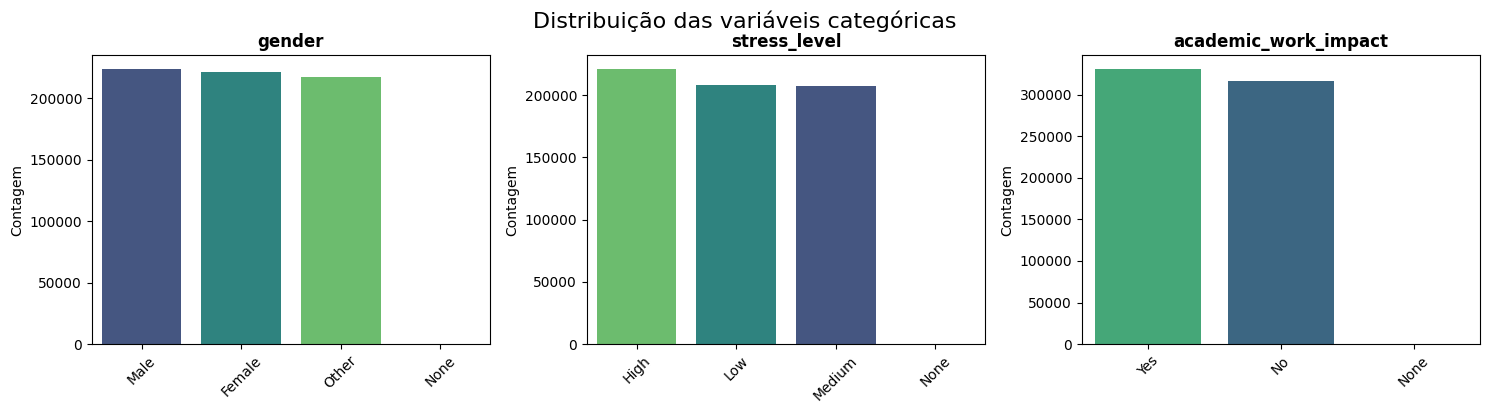

In [51]:
plot_countplot( df_train )

In [52]:
# ═════════════════════════════════════════════════════════════════
# 1. ORDINAL ENCODING
# ═════════════════════════════════════════════════════════════════
def ordinal_encoding(
    df: pl.DataFrame,
    col: str,
    mapping: Optional[Dict] = None,
    suffix: str = "_ordinal"
) -> pl.DataFrame:
    """
    Converte categoria ordinal em números inteiros.
    
    Se mapping for None, ordena alfabeticamente e atribui 1, 2, 3...
    """
    if mapping is None:
        unique_vals = df[col].drop_nulls().unique(maintain_order=True).to_list()
        mapping = {v: i + 1 for i, v in enumerate(unique_vals)}
        print(f"📊 Mapeamento ordinal para '{col}': {mapping}")
    
    new_col = f"{col}{suffix}"
    return df.with_columns(
        pl.col(col).replace(mapping).cast(pl.Int64).alias(new_col)
    )

In [53]:
# ═════════════════════════════════════════════════════════════════
# 2. ONE-HOT ENCODING
# ═════════════════════════════════════════════════════════════════
def one_hot_encoding(
    df: pl.DataFrame,
    col: str,
    drop_first: bool = False
) -> pl.DataFrame:
    """
    Cria colunas binárias para cada categoria.
    drop_first=True remove a primeira dummy (evita multicolinearidade).
    """
    dummies = df[col].to_dummies()
    
    if drop_first:
        first_col = dummies.columns[0]
        dummies = dummies.drop(first_col)
    
    return df.with_columns(dummies)


In [54]:
# ═════════════════════════════════════════════════════════════════
# 3. TARGET ENCODING
# ═════════════════════════════════════════════════════════════════
def target_encoding(
    df: pl.DataFrame,
    col: str,
    target: str,
    test_df: Optional[pl.DataFrame] = None,
    smoothing: Optional[float] = None,
    suffix: str = "_target"
) -> Union[pl.DataFrame, tuple]:
    """
    Substitui categoria pela média do target.
    
    smoothing: fator de suavização contra a média global (útil para categorias raras)
    Se test_df for fornecido, retorna (df_treino, df_teste)
    """
    global_mean = df[target].mean()
    
    if smoothing:
        n = df.group_by(col).agg(pl.count().alias("n"))
        means = df.group_by(col).agg(pl.mean(target).alias("encoded"))
        means = means.join(n, on=col, how="left")
        means = means.with_columns(
            ((pl.col("encoded") * pl.col("n") + global_mean * smoothing) /
             (pl.col("n") + smoothing)).alias("encoded_smooth")
        )
        mapping = dict(zip(means[col].to_list(), means["encoded_smooth"].to_list()))
    else:
        means = df.group_by(col).agg(pl.mean(target).alias("encoded"))
        mapping = dict(zip(means[col].to_list(), means["encoded"].to_list()))
    
    new_col = f"{col}{suffix}"
    
    df_encoded = df.with_columns(
        pl.col(col).replace(mapping).alias(new_col)
    )
    
    if test_df is not None:
        test_encoded = test_df.with_columns(
            pl.col(col).replace(mapping).alias(new_col)
        )
        # Preenche categorias desconhecidas com média global
        test_encoded = test_encoded.with_columns(
            pl.col(new_col).fill_null(global_mean)
        )
        return df_encoded, test_encoded
    
    return df_encoded

In [55]:
# ═════════════════════════════════════════════════════════════════
# 4. FREQUENCY ENCODING
# ═════════════════════════════════════════════════════════════════
def frequency_encoding(
    df: pl.DataFrame,
    col: str,
    use_relative: bool = True,
    suffix: str = "_freq"
) -> pl.DataFrame:
    """
    Substitui categoria pela frequência (ou contagem absoluta).
    """
    if use_relative:
        total = df.height
        agg_expr = (pl.count() / total).alias("freq")
    else:
        agg_expr = pl.count().alias("freq")
    
    freqs = df.group_by(col).agg(agg_expr)
    mapping = dict(zip(freqs[col].to_list(), freqs["freq"].to_list()))
    
    new_col = f"{col}{suffix}"
    return df.with_columns(
        pl.col(col).replace(mapping).alias(new_col)
    )

In [56]:
# ═════════════════════════════════════════════════════════════════
# 5. BINARY ENCODING
# ═════════════════════════════════════════════════════════════════
def binary_encoding(
    df: pl.DataFrame,
    col: str,
    suffix: str = "_bin"
) -> pl.DataFrame:
    """
    Converte categoria em representação binária compacta.
    Ex: 7 categorias → 3 colunas binárias.
    """
    unique_vals = df[col].drop_nulls().unique(maintain_order=True).to_list()
    n_bits = int(np.ceil(np.log2(max(len(unique_vals), 2))))
    
    # Mapeia categoria → número inteiro
    cat_to_int = {val: i for i, val in enumerate(unique_vals)}
    
    # Cria colunas binárias
    new_cols = {}
    for bit in range(n_bits):
        bit_name = f"{col}{suffix}{bit}"
        new_cols[bit_name] = [
            (cat_to_int.get(val, 0) >> bit) & 1 if val is not None else None
            for val in df[col].to_list()
        ]
    
    return df.with_columns([
        pl.Series(name, vals).cast(pl.Int8) for name, vals in new_cols.items()
    ])


In [57]:
# ═════════════════════════════════════════════════════════════════
# 6. HASH ENCODING
# ═════════════════════════════════════════════════════════════════
def hash_encoding(
    df: pl.DataFrame,
    col: str,
    n_components: int = 8,
    suffix: str = "_hash"
) -> pl.DataFrame:
    """
    Converte categoria em hash com número fixo de componentes.
    Útil para cardinalidade muito alta.
    """
    return df.with_columns(
        (pl.col(col).cast(pl.Utf8).hash() % n_components).alias(f"{col}{suffix}")
    )


In [58]:
# ═════════════════════════════════════════════════════════════════
# 7. FUNÇÃO INTELIGENTE: AUTO_ENCODE
# ═════════════════════════════════════════════════════════════════


def auto_encode(
    df: pl.DataFrame,
    target: Optional[str] = None,
    cols: Optional[List[str]] = None,
    exclude: Optional[List[str]] = None,  # ← AQUI está o parâmetro que faltava
    max_one_hot: int = 15,
    ordinal_mappings: Optional[Dict[str, Dict]] = None,
    test_df: Optional[pl.DataFrame] = None
) -> Union[pl.DataFrame, tuple]:
    """
    Aplica o encoding ideal automaticamente para cada coluna categórica.
    
    Parâmetros:
    -----------
    df : pl.DataFrame
        DataFrame de treino
    target : str, optional
        Nome da coluna alvo
    cols : list, optional
        Colunas para codificar (se None, detecta automaticamente)
    exclude : list, optional
        Colunas que NÃO devem ser codificadas
    max_one_hot : int
        Limite máximo de categorias para One-Hot
    ordinal_mappings : dict, optional
        Dicionário de mapeamentos ordinais
    test_df : pl.DataFrame, optional
        DataFrame de teste para aplicar os mesmos encodings
    """
    
    # Detecta colunas categóricas automaticamente
    if cols is None:
        cols = [c for c in df.columns if not df[c].dtype.is_numeric()]
    
    # Remove colunas excluídas
    if exclude:
        cols = [c for c in cols if c not in exclude]
    
    # Remove target da lista, se existir
    if target and target in cols:
        cols.remove(target)
    
    ordinal_mappings = ordinal_mappings or {}
    df_result = df.clone()
    test_result = test_df.clone() if test_df is not None else None
    
    print(f"🔍 Colunas a codificar: {cols}\n")
    
    for col in cols:
        n_unique = df_result[col].n_unique()
        n_nulls = df_result[col].null_count()
        pct_unique = (n_unique / df_result.height) * 100
        
        print(f"📌 {col}: {n_unique} categorias | {n_nulls} nulos | {pct_unique:.2f}% únicos")
        
        # Coluna constante
        if n_unique == 1:
            print(f"   ⚠️  Removida (constante)\n")
            df_result = df_result.drop(col)
            if test_result is not None:
                test_result = test_result.drop(col)
            continue
        
        # Ordinal (prioridade máxima se mapping informado)
        if col in ordinal_mappings:
            print(f"   ✅ Aplicado: Ordinal Encoding\n")
            df_result = ordinal_encoding(df_result, col, ordinal_mappings[col])
            if test_result is not None:
                test_result = ordinal_encoding(test_result, col, ordinal_mappings[col])
        
        # One-Hot
        elif n_unique <= max_one_hot:
            print(f"   ✅ Aplicado: One-Hot Encoding\n")
            df_result = one_hot_encoding(df_result, col)
            if test_result is not None:
                test_result = one_hot_encoding(test_result, col)
        
        # Target Encoding (se target disponível)
        elif target is not None and target in df_result.columns:
            print(f"   ✅ Aplicado: Target Encoding\n")
            if test_result is not None:
                df_result, test_result = target_encoding(
                    df_result, col, target, test_result
                )
            else:
                df_result = target_encoding(df_result, col, target)
        
        # Frequency Encoding
        elif n_unique <= 50:
            print(f"   ✅ Aplicado: Frequency Encoding\n")
            df_result = frequency_encoding(df_result, col)
            if test_result is not None:
                test_result = frequency_encoding(test_result, col)
        
        # Hash Encoding (cardinalidade muito alta)
        else:
            print(f"   ✅ Aplicado: Hash Encoding\n")
            df_result = hash_encoding(df_result, col)
            if test_result is not None:
                test_result = hash_encoding(test_result, col)
    
    if test_result is not None:
        return df_result, test_result
    
    return df_result


In [59]:
mapeamento_ordinal = {
        # "sleep_quality_ordinal_encoder": { "null": 1, "poor": 2, "average": 3, "good": 4 }
    }

In [60]:
excluir  = ["id"]

In [61]:
 df_encoded = auto_encode(df_train, 
                          target="health_condition", 
                          exclude=excluir,
                          ordinal_mappings=mapeamento_ordinal
                         )

🔍 Colunas a codificar: ['gender', 'stress_level', 'academic_work_impact']

📌 gender: 4 categorias | 29034 nulos | 0.00% únicos
   ✅ Aplicado: One-Hot Encoding

📌 stress_level: 4 categorias | 55148 nulos | 0.00% únicos
   ✅ Aplicado: One-Hot Encoding

📌 academic_work_impact: 3 categorias | 44224 nulos | 0.00% únicos
   ✅ Aplicado: One-Hot Encoding



In [62]:
 df_test_encoded = auto_encode(df_test, 
                          target="health_condition", 
                          exclude=excluir,
                          ordinal_mappings=mapeamento_ordinal
                              )

🔍 Colunas a codificar: ['gender', 'stress_level', 'academic_work_impact']

📌 gender: 4 categorias | 14212 nulos | 0.00% únicos
   ✅ Aplicado: One-Hot Encoding

📌 stress_level: 4 categorias | 19626 nulos | 0.00% únicos
   ✅ Aplicado: One-Hot Encoding

📌 academic_work_impact: 3 categorias | 25721 nulos | 0.00% únicos
   ✅ Aplicado: One-Hot Encoding



In [63]:
# df_train.select(cs.numeric()).fill_null(0).corr().sort(['health_condition'])

In [64]:
df_train

id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,i64
0,24.0,null,1.83,1.59,2.11,7.46,122.0,38.0,8.63,"""Male""","""Medium""","""No""",1
1,19.0,5.97,1.08,null,3.03,8.22,76.0,19.0,null,"""Female""","""Medium""","""No""",0
2,18.0,5.09,null,null,null,6.25,134.0,60.0,7.47,"""Female""","""Low""","""Yes""",0
3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,"""Other""","""Low""",null,1
4,26.0,11.2,1.87,2.81,1.95,5.25,null,null,13.39,"""Female""","""Medium""","""No""",1
…,…,…,…,…,…,…,…,…,…,…,…,…,…
691364,22.0,10.78,3.25,1.57,1.65,7.71,86.0,94.0,12.89,"""Male""",null,"""No""",1
691365,20.0,3.45,1.86,0.89,0.3,6.59,221.0,42.0,8.47,"""Female""","""High""","""No""",1
691366,null,null,null,null,2.06,6.16,null,86.0,7.79,"""Other""","""Medium""","""No""",1


In [65]:
df_encoded

id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label,gender_Female,gender_Male,gender_Other,gender_null,stress_level_High,stress_level_Low,stress_level_Medium,stress_level_null,academic_work_impact_No,academic_work_impact_Yes,academic_work_impact_null
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,i64,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8
0,24.0,null,1.83,1.59,2.11,7.46,122.0,38.0,8.63,"""Male""","""Medium""","""No""",1,0,1,0,0,0,0,1,0,1,0,0
1,19.0,5.97,1.08,null,3.03,8.22,76.0,19.0,null,"""Female""","""Medium""","""No""",0,1,0,0,0,0,0,1,0,1,0,0
2,18.0,5.09,null,null,null,6.25,134.0,60.0,7.47,"""Female""","""Low""","""Yes""",0,1,0,0,0,0,1,0,0,0,1,0
3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,"""Other""","""Low""",null,1,0,0,1,0,0,1,0,0,0,0,1
4,26.0,11.2,1.87,2.81,1.95,5.25,null,null,13.39,"""Female""","""Medium""","""No""",1,1,0,0,0,0,0,1,0,1,0,0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
691364,22.0,10.78,3.25,1.57,1.65,7.71,86.0,94.0,12.89,"""Male""",null,"""No""",1,0,1,0,0,0,0,0,1,1,0,0
691365,20.0,3.45,1.86,0.89,0.3,6.59,221.0,42.0,8.47,"""Female""","""High""","""No""",1,1,0,0,0,1,0,0,0,1,0,0
691366,null,null,null,null,2.06,6.16,null,86.0,7.79,"""Other""","""Medium""","""No""",1,0,0,1,0,0,0,1,0,1,0,0


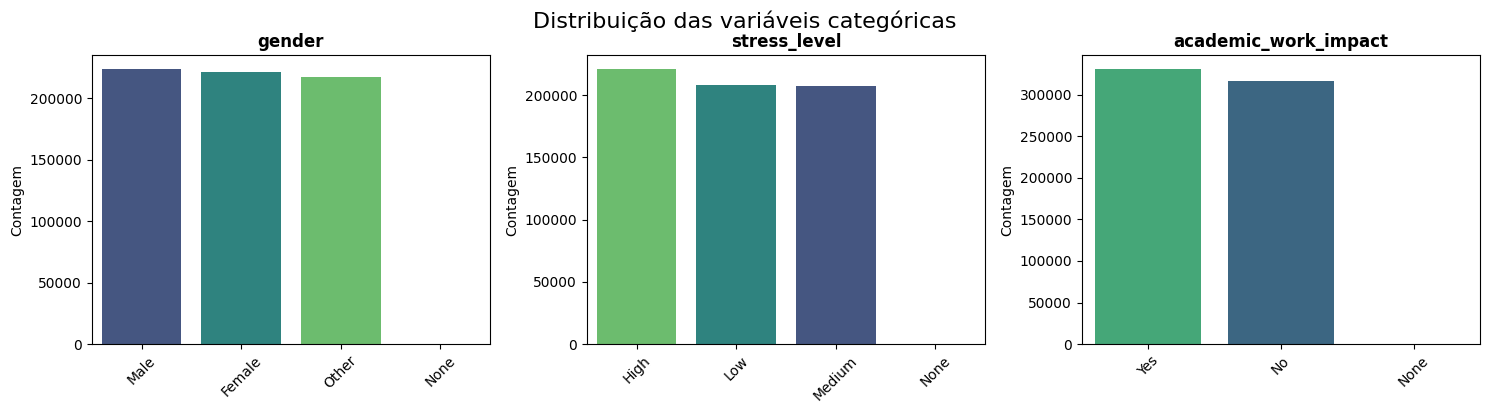

In [66]:
#Antes do encoded
plot_countplot( df_train )

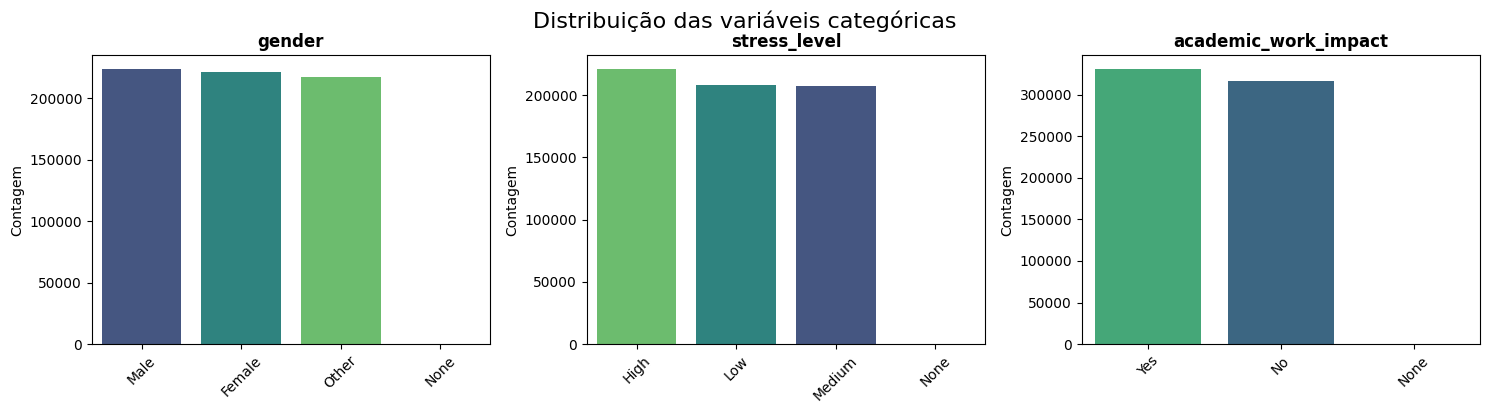

In [67]:
#Depois do encoded
plot_countplot( df_encoded )

In [68]:
def plot_distribuicao_grid_4(
    df: pl.DataFrame,
    cols: Optional[List[str]] = None,
    bins: int = 20,
    figsize: tuple = (14, 10),
    limite_categorica: int = 20
) -> None:
    """Versão com 4 gráficos por vez (2×2)."""

    if cols is None:
        cols = df.columns

    total = len(cols)
    linhas = math.ceil(total / 4)
    idx = 0

    for linha in range(linhas):
        fig, axes = plt.subplots(2, 2, figsize=figsize)
        axes = axes.flatten()
        fig.suptitle(f"Distribuições ({linha + 1}/{linhas})", fontsize=14, fontweight="bold")

        for j in range(4):
            ax = axes[j]

            if idx < total:
                col = cols[idx]
                n_unique = df[col].n_unique()
                is_numeric = df[col].dtype.is_numeric()

                if not is_numeric or n_unique <= limite_categorica:
                    valores = df[col].value_counts().sort("count", descending=True)
                    sns.countplot(
                        data=df.to_pandas(),
                        x=col,
                        order=valores[col].to_list(),
                        ax=ax
                    )
                    ax.set_title(f"{col} ({n_unique} únicos)", fontsize=10)
                    ax.tick_params(axis="x", rotation=45)
                else:
                    sns.histplot(
                        data=df.to_pandas(),
                        x=col,
                        bins=bins,
                        kde=True,
                        stat="density",
                        ax=ax
                    )
                    ax.set_title(f"{col} ({n_unique} únicos)", fontsize=10)
                    ax.set_ylabel("Densidade")
            else:
                ax.set_visible(False)

            idx += 1

        plt.tight_layout()
        plt.show()

    print(f"\n📊 {total} colunas em {linhas} grid(s) 2×2")


In [69]:

def plot_distribuicao_grid(
    df: pl.DataFrame,
    cols: Optional[List[str]] = None,
    bins: int = 20,
    figsize: tuple = (18, 5),
    limite_categorica: int = 20
) -> None:
    """
    Plota gráficos de distribuição 3 por vez em subplots.
    Cada linha da grid = 3 colunas.

    Parâmetros:
    -----------
    df : pl.DataFrame
    cols : list, optional
        Lista de colunas. Se None, usa todas.
    bins : int
        Número de bins para histogramas.
    figsize : tuple
        Tamanho da figura (largura, altura).
    limite_categorica : int
        Até quantos valores únicos considerar como categórica.
    """

    if cols is None:
        cols = df.columns

    total = len(cols)
    linhas = math.ceil(total / 3)

    idx = 0

    for linha in range(linhas):
        # Cria uma nova figura com 3 subplots por linha
        fig, axes = plt.subplots(1, 3, figsize=figsize)
        fig.suptitle(f"Distribuições ({linha + 1}/{linhas})", fontsize=14, fontweight="bold")

        for j in range(3):
            ax = axes[j]

            if idx < total:
                col = cols[idx]
                n_unique = df[col].n_unique()
                is_numeric = df[col].dtype.is_numeric()

                # Escolhe o tipo de gráfico
                if not is_numeric or n_unique <= limite_categorica:
                    # Countplot
                    valores = df[col].value_counts().sort("count", descending=True)
                    sns.countplot(
                        data=df.to_pandas(),
                        x=col,
                        order=valores[col].to_list(),
                        ax=ax
                    )
                    ax.set_title(f"{col}\n({n_unique} únicos)", fontsize=11)
                    ax.tick_params(axis="x", rotation=45)
                else:
                    # Histograma + KDE
                    sns.histplot(
                        data=df.to_pandas(),
                        x=col,
                        bins=bins,
                        kde=True,
                        stat="density",
                        ax=ax
                    )
                    ax.set_title(f"{col}\n({n_unique} únicos)", fontsize=11)
                    ax.set_ylabel("Densidade")

            else:
                # Subplot vazio: esconde
                ax.set_visible(False)

            idx += 1

        plt.tight_layout()
        plt.show()

    print(f"\n📊 {total} colunas plotadas em {linhas} linha(s) de 3")


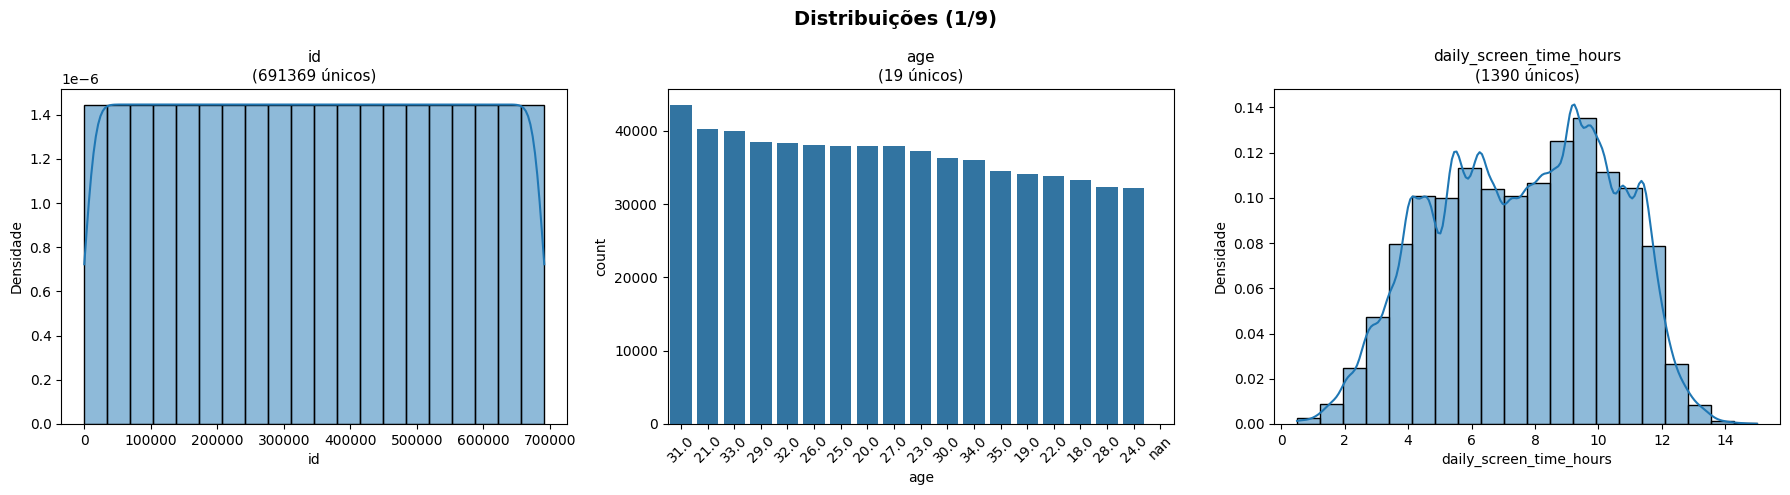

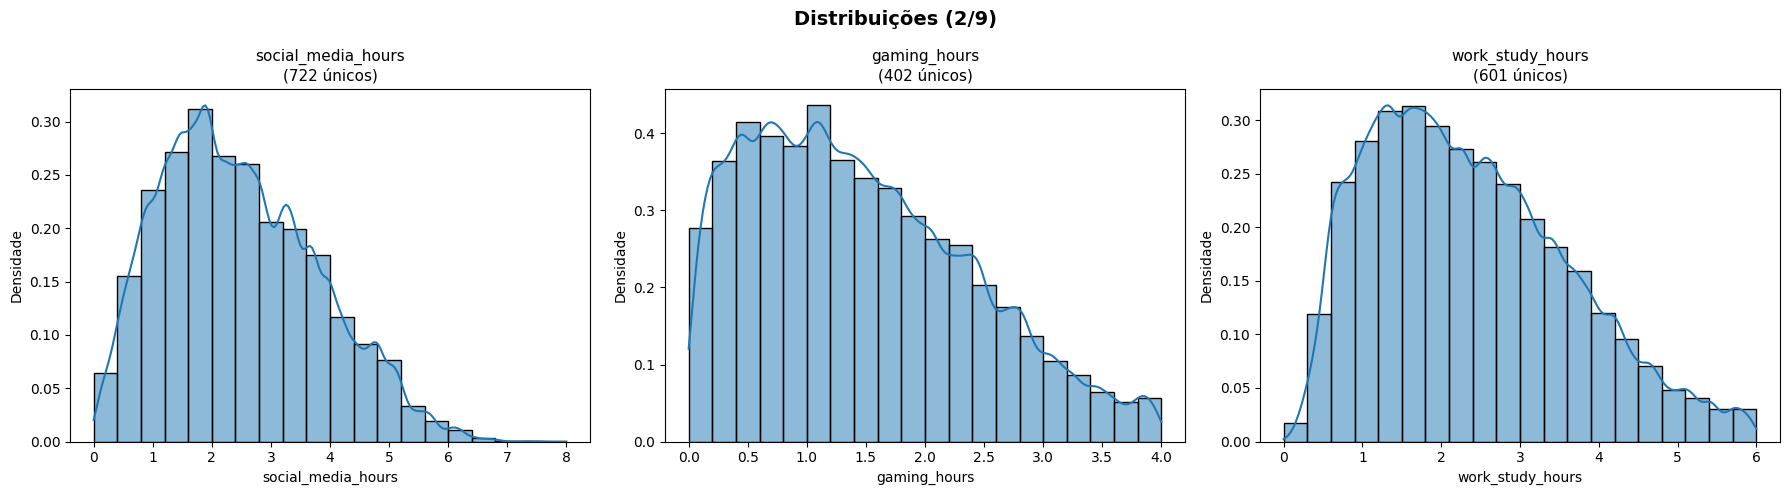

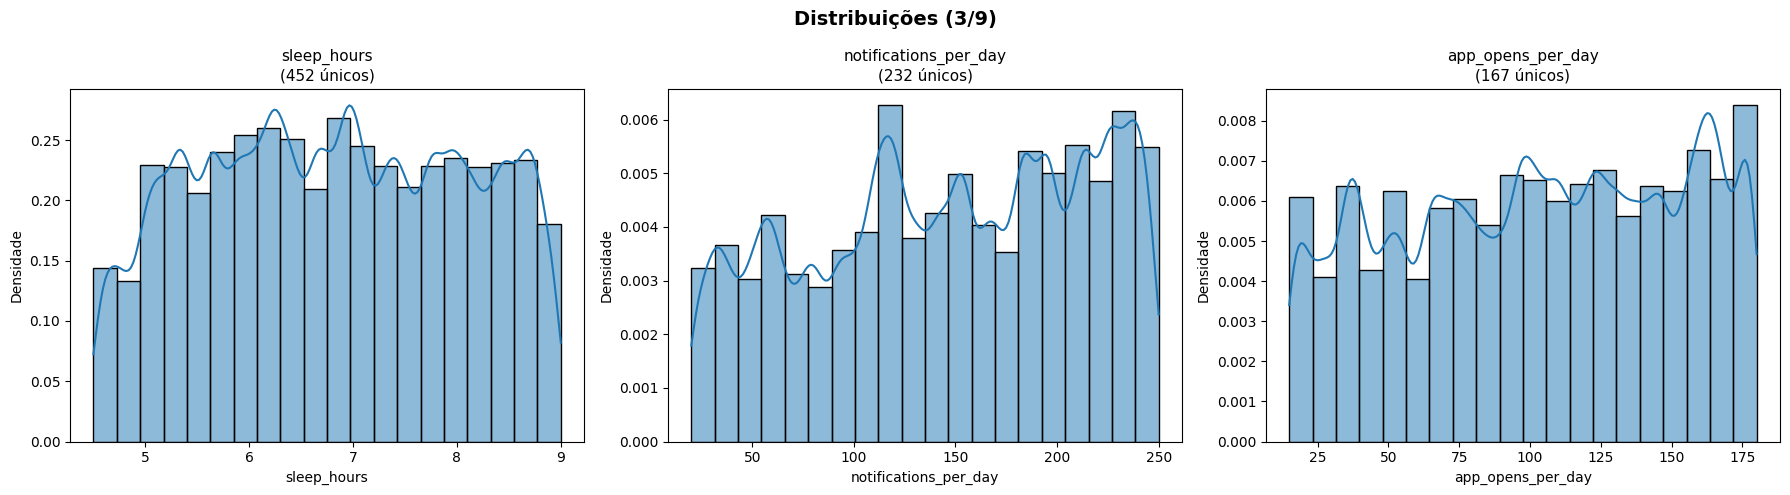

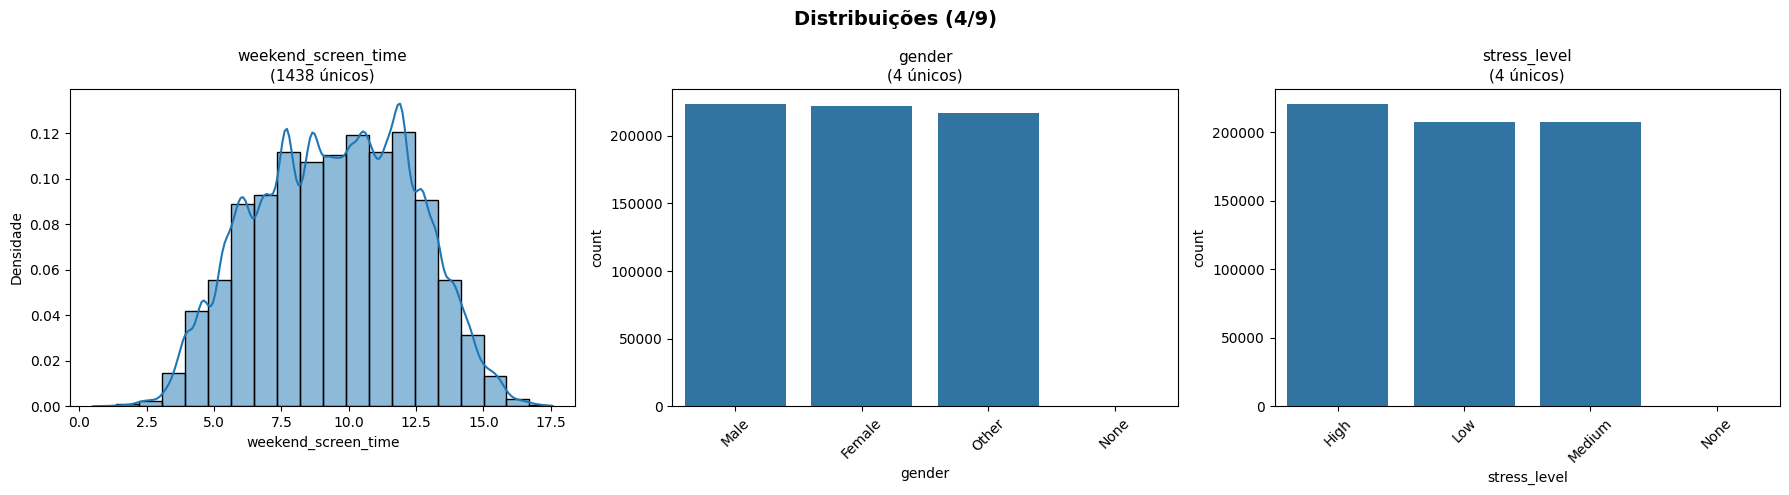

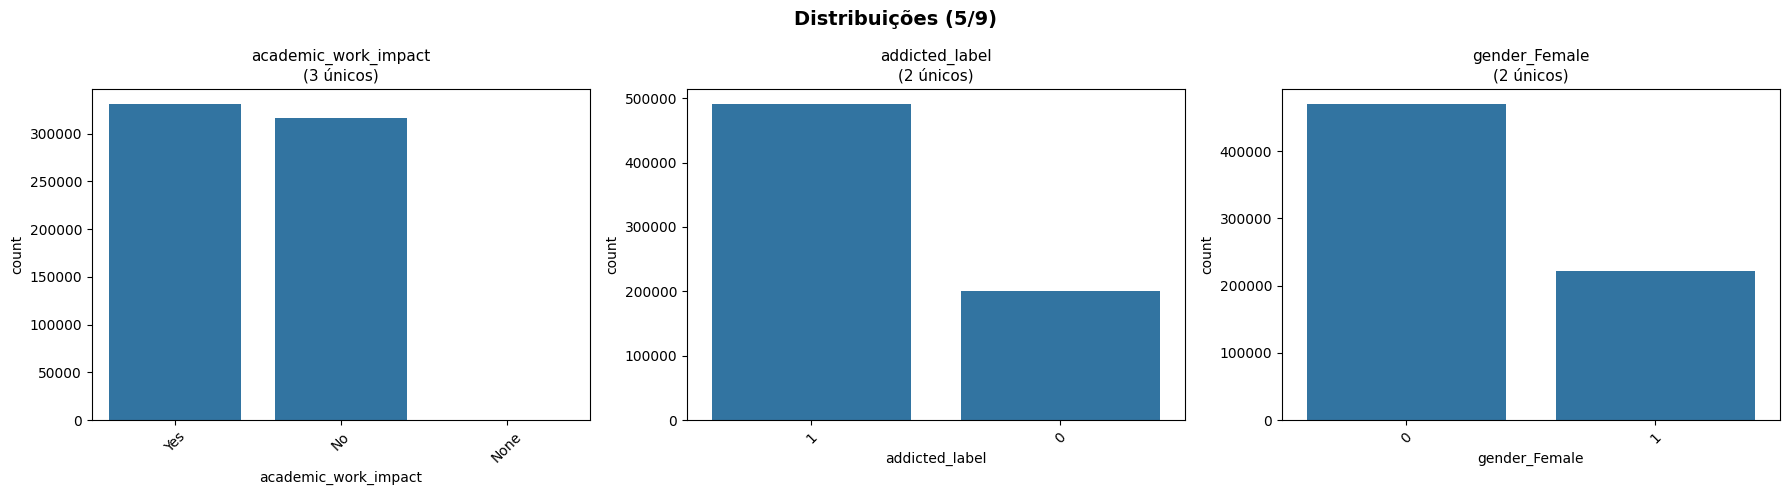

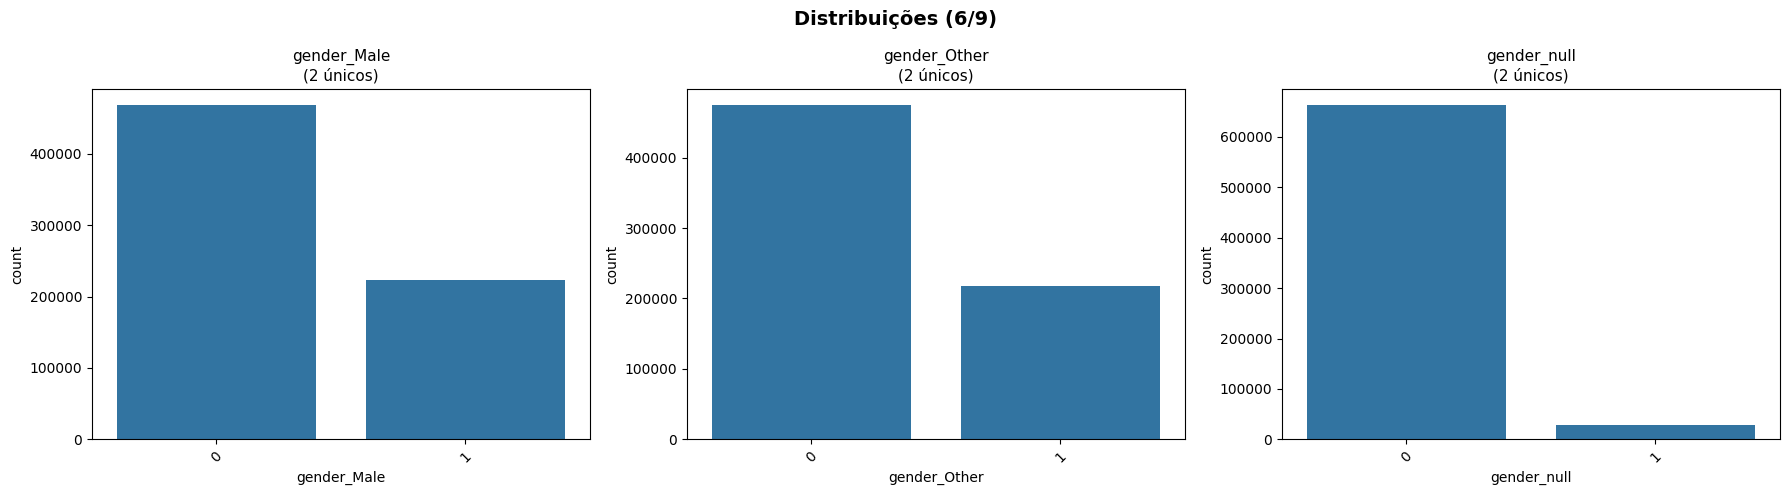

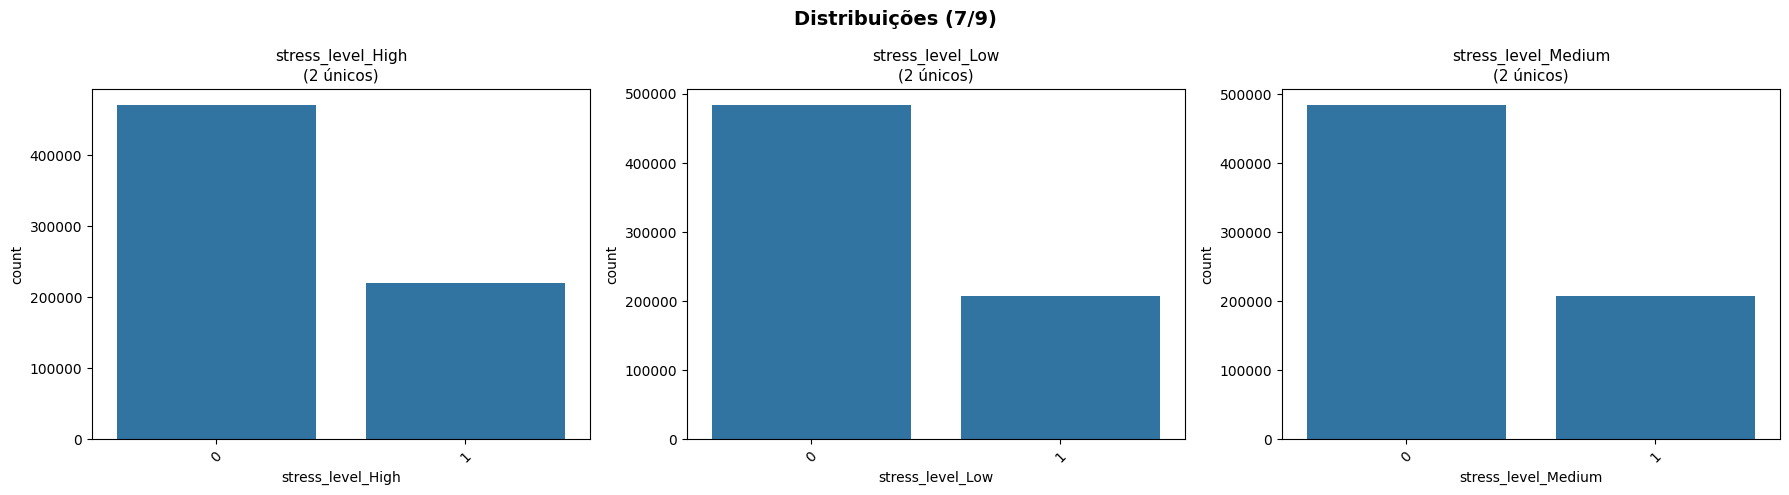

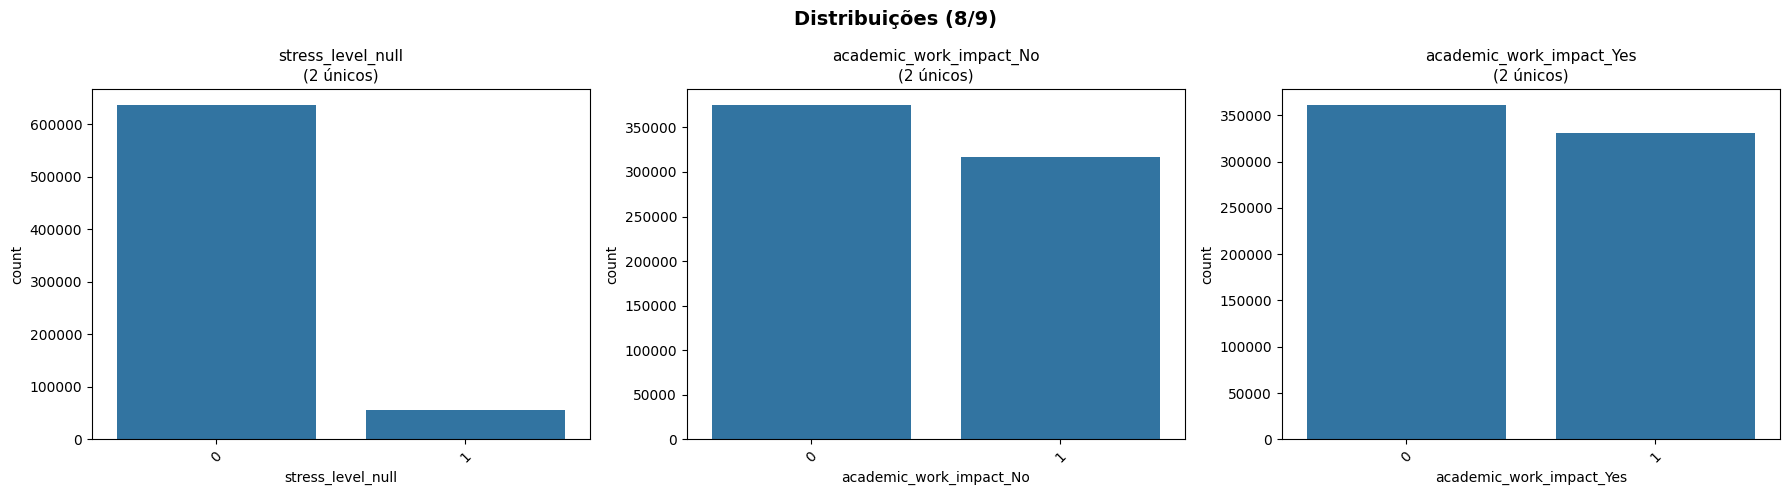

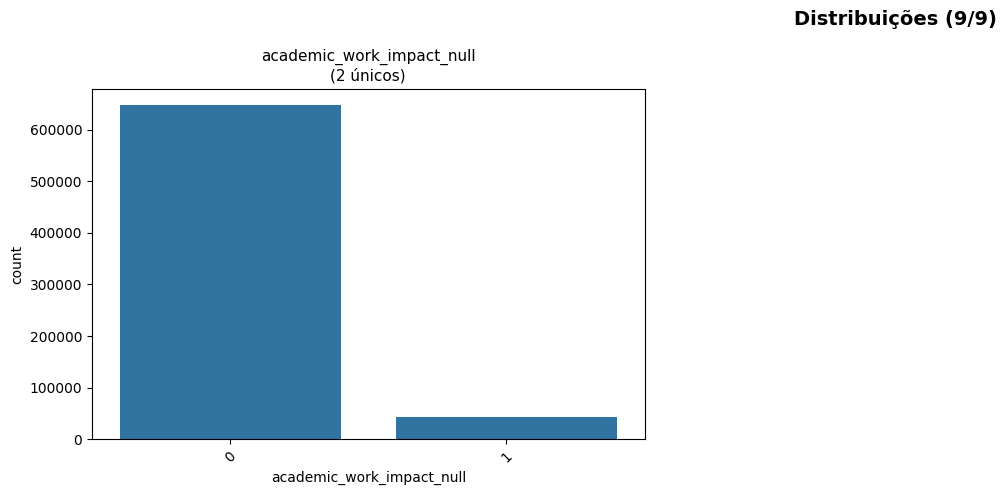


📊 25 colunas plotadas em 9 linha(s) de 3


In [70]:
plot_distribuicao_grid(df_encoded)

In [71]:
corr_matrix = remove_colunas_constantes(df_encoded)


📊 Resultado: 0 removidas | 25 mantidas


In [72]:
corr_matrix = corr_matrix.select(cs.numeric()).corr()
print(corr_matrix)

shape: (22, 22)
┌───────────┬─────┬────────────┬────────────┬───┬────────────┬────────────┬────────────┬───────────┐
│ id        ┆ age ┆ daily_scre ┆ social_med ┆ … ┆ stress_lev ┆ academic_w ┆ academic_w ┆ academic_ │
│ ---       ┆ --- ┆ en_time_ho ┆ ia_hours   ┆   ┆ el_null    ┆ ork_impact ┆ ork_impact ┆ work_impa │
│ f64       ┆ f64 ┆ urs        ┆ ---        ┆   ┆ ---        ┆ _No        ┆ _Yes       ┆ ct_null   │
│           ┆     ┆ ---        ┆ f64        ┆   ┆ f64        ┆ ---        ┆ ---        ┆ ---       │
│           ┆     ┆ f64        ┆            ┆   ┆            ┆ f64        ┆ f64        ┆ f64       │
╞═══════════╪═════╪════════════╪════════════╪═══╪════════════╪════════════╪════════════╪═══════════╡
│ 1.0       ┆ NaN ┆ NaN        ┆ NaN        ┆ … ┆ -0.000613  ┆ 0.001159   ┆ -0.00046   ┆ -0.00142  │
│ NaN       ┆ NaN ┆ NaN        ┆ NaN        ┆ … ┆ NaN        ┆ NaN        ┆ NaN        ┆ NaN       │
│ NaN       ┆ NaN ┆ NaN        ┆ NaN        ┆ … ┆ NaN        ┆ NaN        ┆

In [73]:
def remover_colineares(
    df: pl.DataFrame, 
    threshold: float = 0.95
) -> tuple[pl.DataFrame, list[str]]:
    """
    Remove variáveis altamente correlacionadas (dummy trap).
    
    Parâmetros:
    -----------
    df : pl.DataFrame
        DataFrame numérico
    threshold : float
        Limite de correlação para considerar colinear (padrão: 0.95)
    
    Retorna:
    --------
    df_filtrado : pl.DataFrame
    removidas : list[str]
    """
    corr = df.corr()
    
    # Matriz de correlação como numpy
    corr_matrix = corr.to_numpy()
    cols = corr.columns
    
    removidas = set()
    
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            if abs(corr_matrix[i, j]) >= threshold:
                # Remove a segunda variável do par
                removidas.add(cols[j])
    
    # Remove colunas constantes também
    for col in df.columns:
        std_val = df[col].std()
        if std_val is None or std_val == 0:
            removidas.add(col)
    
    df_filtrado = df.drop(list(removidas))
    
    print(f"✅ Removidas {len(removidas)} colunas colineares:")
    for c in sorted(removidas):
        print(f"   - {c}")
    
    return df_filtrado, list(removidas)

In [74]:
def compute_correlation(df: pl.DataFrame, method: str = "pearson") -> pl.DataFrame:
    """
    Calcula matriz de correlação com suporte a Pearson e Spearman.
    
    Parâmetros:
    -----------
    df : pl.DataFrame
    method : str
        'pearson', 'spearman' ou 'kendall'
    """
    cols = df.columns
    n = len(cols)
    matrix = np.eye(n)
    
    for i in range(n):
        for j in range(i + 1, n):
            x = df[cols[i]].to_numpy()
            y = df[cols[j]].to_numpy()
            
            # Remove NaN
            mask = ~(np.isnan(x) | np.isnan(y))
            x_clean = x[mask]
            y_clean = y[mask]
            
            if len(x_clean) < 3:
                matrix[i, j] = matrix[j, i] = np.nan
                continue
            
            if method == "pearson":
                corr_val, _ = stats.pearsonr(x_clean, y_clean)
            elif method == "spearman":
                corr_val, _ = stats.spearmanr(x_clean, y_clean)
            elif method == "kendall":
                corr_val, _ = stats.kendalltau(x_clean, y_clean)
            else:
                raise ValueError(f"Método inválido: {method}")
            
            matrix[i, j] = matrix[j, i] = corr_val
    
    # Converte para DataFrame Polars
    rows = []
    for i, col_name in enumerate(cols):
        row_dict = {"column": col_name}
        for j, col_j in enumerate(cols):
            row_dict[col_j] = matrix[i, j]
        rows.append(row_dict)
    
    return pl.DataFrame(rows)

In [75]:
def plot_correlation_heatmap(
    df: pl.DataFrame,
    method: str = "spearman",
    figsize: tuple = (14, 12),
    annot_size: int = 8,
    label_size: int = 9,
    title: str = None,
    save_path: str = None,
    vmin: float = -1.0,
    vmax: float = 1.0,
    show_values: bool = True,
    value_threshold: float = 0.1
) -> plt.Figure:
    """
    Gera heatmap de correlação profissional e legível.
    """
    # Calcula correlação
    corr = compute_correlation(df, method=method)
    
    # Remove coluna de nomes se existir
    if "column" in corr.columns:
        corr_numeric = corr.drop("column")
    else:
        corr_numeric = corr
    
    corr_matrix = corr_numeric.to_numpy()
    columns = corr_numeric.columns
    
    # Configura estilo
    sns.set_style("whitegrid")
    sns.set_context("notebook", font_scale=1.0)
    
    fig, ax = plt.subplots(figsize=figsize)
    
    # Paleta de cores divergente
    cmap = sns.diverging_palette(220, 10, as_cmap=True)
    
    # Triangular inferior
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    
    heatmap = sns.heatmap(
        corr_matrix,
        mask=mask,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        center=0,
        square=True,
        linewidths=0.5,
        linecolor='white',
        cbar_kws={"shrink": 0.8, "label": f"Correlação ({method})"},
        ax=ax,
        annot=show_values,
        fmt=".2f",
        annot_kws={"size": annot_size}
    )
    
    # Labels
    ax.set_xticklabels(columns, rotation=45, ha="right", fontsize=label_size)
    ax.set_yticklabels(columns, rotation=0, fontsize=label_size)
    
    # Título
    if title is None:
        title = f"Matriz de Correlação ({method.capitalize()})"
    ax.set_title(title, fontsize=14, fontweight="bold", pad=20)
    
    # Oculta valores pequenos
    if show_values and value_threshold > 0:
        for text in ax.texts:
            try:
                val = float(text.get_text())
                if abs(val) < value_threshold:
                    text.set_text("")
            except ValueError:
                pass
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"✅ Gráfico salvo em: {save_path}")
    
    return fig

In [76]:
def analyze_correlation(
    df: pl.DataFrame,
    method: str = "spearman",
    colinear_threshold: float = 0.95,
    value_threshold: float = 0.1,
    save_path: str = None,
    exclude_columns: list[str] = None
) -> tuple[pl.DataFrame, plt.Figure]:
    """
    Pipeline completo: filtra e gera heatmap.
    
    Parâmetros:
    -----------
    exclude_columns : list[str], opcional
        Lista de colunas para excluir manualmente (ex: ['id', 'name', 'date'])
    """
    print("=" * 60)
    print(f" ANÁLISE DE CORRELAÇÃO ({method.upper()})")
    print("=" * 60)
    
    # 0. Remove colunas de identificação/excluir
    if exclude_columns is None:
        exclude_columns = []
    
    # Padrões comuns de colunas para excluir
    padroes_excluir = ['id', 'name', 'date', 'time', 'label', 'category']
    cols_excluir = [c for c in df.columns if c.lower() in padroes_excluir]
    cols_excluir.extend(exclude_columns)
    
    if cols_excluir:
        print(f"\n🚫 Excluindo colunas de identificação:")
        for c in set(cols_excluir):
            print(f"   - {c}")
        df = df.drop(set(cols_excluir))
    
    # 1. Só numéricas - filtro explícito
    df_num = df.select(cs.numeric())
    
    # Validação: garante que todas são numéricas
    for col in df_num.columns:
        if df_num[col].dtype not in [pl.Float32, pl.Float64, pl.Int32, pl.Int64]:
            print(f"⚠️  Coluna {col} não é numérica, removendo...")
            df_num = df_num.drop(col)
    
    print(f"\n📊 Total de variáveis numéricas: {len(df_num.columns)}")
    
    if len(df_num.columns) == 0:
        raise ValueError("Nenhuma coluna numérica encontrada após filtragem!")
    
    # 2. Remove constantes
    constantes = [
        c for c in df_num.columns 
        if df_num[c].std() is None or df_num[c].std() == 0
    ]
    if constantes:
        print(f"\n⚠️  Removidas {len(constantes)} colunas constantes:")
        for c in constantes:
            print(f"   - {c}")
        df_num = df_num.drop(constantes)
    
    if len(df_num.columns) == 0:
        raise ValueError("Todas as colunas foram removidas! Verifique seus dados.")
    
    # 3. Remove colineares
    df_filtrado, removidas = remover_colineares(df_num, colinear_threshold)
    print(f"\n✅ Variáveis restantes: {len(df_filtrado.columns)}")
    
    if len(df_filtrado.columns) < 2:
        raise ValueError("Menos de 2 variáveis restantes para correlação!")
    
    # 4. Gera heatmap
    print(f"\n📈 Gerando heatmap de correlação {method}...")
    fig = plot_correlation_heatmap(
        df_filtrado,
        method=method,
        figsize=(max(12, len(df_filtrado.columns) * 0.8), 
                 max(10, len(df_filtrado.columns) * 0.7)),
        annot_size=8,
        label_size=10,
        title=f"Correlação de {method.capitalize()} (filtrada)",
        save_path=save_path,
        show_values=True,
        value_threshold=value_threshold
    )
    
    plt.show()
    
    return df_filtrado, fig

In [77]:
df_encoded

id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label,gender_Female,gender_Male,gender_Other,gender_null,stress_level_High,stress_level_Low,stress_level_Medium,stress_level_null,academic_work_impact_No,academic_work_impact_Yes,academic_work_impact_null
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,i64,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8
0,24.0,null,1.83,1.59,2.11,7.46,122.0,38.0,8.63,"""Male""","""Medium""","""No""",1,0,1,0,0,0,0,1,0,1,0,0
1,19.0,5.97,1.08,null,3.03,8.22,76.0,19.0,null,"""Female""","""Medium""","""No""",0,1,0,0,0,0,0,1,0,1,0,0
2,18.0,5.09,null,null,null,6.25,134.0,60.0,7.47,"""Female""","""Low""","""Yes""",0,1,0,0,0,0,1,0,0,0,1,0
3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,"""Other""","""Low""",null,1,0,0,1,0,0,1,0,0,0,0,1
4,26.0,11.2,1.87,2.81,1.95,5.25,null,null,13.39,"""Female""","""Medium""","""No""",1,1,0,0,0,0,0,1,0,1,0,0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
691364,22.0,10.78,3.25,1.57,1.65,7.71,86.0,94.0,12.89,"""Male""",null,"""No""",1,0,1,0,0,0,0,0,1,1,0,0
691365,20.0,3.45,1.86,0.89,0.3,6.59,221.0,42.0,8.47,"""Female""","""High""","""No""",1,1,0,0,0,1,0,0,0,1,0,0
691366,null,null,null,null,2.06,6.16,null,86.0,7.79,"""Other""","""Medium""","""No""",1,0,0,1,0,0,0,1,0,1,0,0


 ANÁLISE DE CORRELAÇÃO (SPEARMAN)

🚫 Excluindo colunas de identificação:
   - id
⚠️  Coluna gender_Female não é numérica, removendo...
⚠️  Coluna gender_Male não é numérica, removendo...
⚠️  Coluna gender_Other não é numérica, removendo...
⚠️  Coluna gender_null não é numérica, removendo...
⚠️  Coluna stress_level_High não é numérica, removendo...
⚠️  Coluna stress_level_Low não é numérica, removendo...
⚠️  Coluna stress_level_Medium não é numérica, removendo...
⚠️  Coluna stress_level_null não é numérica, removendo...
⚠️  Coluna academic_work_impact_No não é numérica, removendo...
⚠️  Coluna academic_work_impact_Yes não é numérica, removendo...
⚠️  Coluna academic_work_impact_null não é numérica, removendo...

📊 Total de variáveis numéricas: 10
✅ Removidas 0 colunas colineares:

✅ Variáveis restantes: 10

📈 Gerando heatmap de correlação spearman...
✅ Gráfico salvo em: correlation_heatmap.png


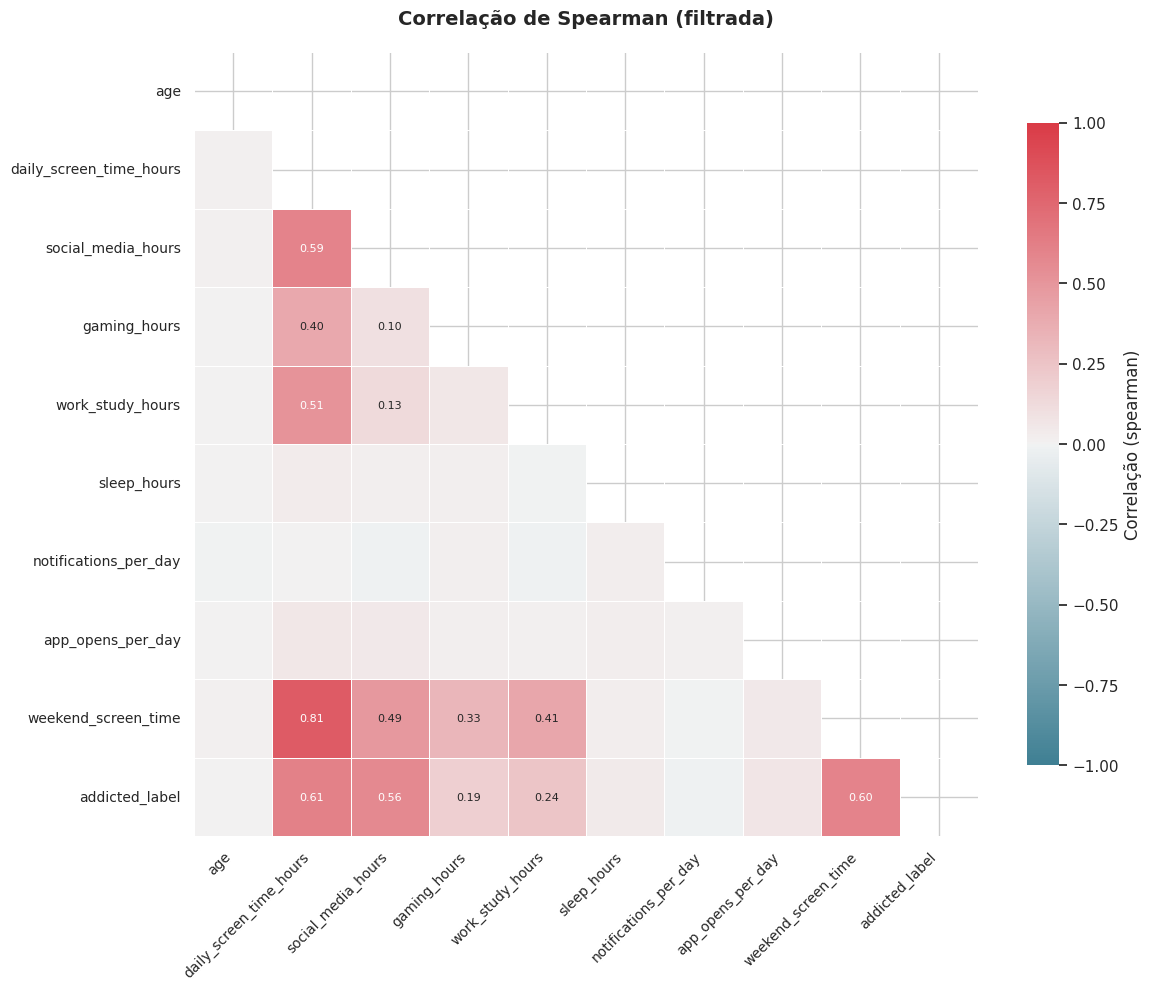

In [78]:
# Supondo que seu DataFrame se chama df_encoded

# Se precisar excluir colunas específicas manualmente:
df_filtrado, fig = analyze_correlation(
    df_encoded,
    method="spearman",
    colinear_threshold=0.95,
    value_threshold=0.1,
    save_path="correlation_heatmap.png",
    exclude_columns=['id']  # adicione as colunas que precisam excluir
)



In [79]:
df_encoded.select(cs.numeric() - cs.by_name("id"))

age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,addicted_label,gender_Female,gender_Male,gender_Other,gender_null,stress_level_High,stress_level_Low,stress_level_Medium,stress_level_null,academic_work_impact_No,academic_work_impact_Yes,academic_work_impact_null
f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8
24.0,null,1.83,1.59,2.11,7.46,122.0,38.0,8.63,1,0,1,0,0,0,0,1,0,1,0,0
19.0,5.97,1.08,null,3.03,8.22,76.0,19.0,null,0,1,0,0,0,0,0,1,0,1,0,0
18.0,5.09,null,null,null,6.25,134.0,60.0,7.47,0,1,0,0,0,0,1,0,0,0,1,0
21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,1,0,0,1,0,0,1,0,0,0,0,1
26.0,11.2,1.87,2.81,1.95,5.25,null,null,13.39,1,1,0,0,0,0,0,1,0,1,0,0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
22.0,10.78,3.25,1.57,1.65,7.71,86.0,94.0,12.89,1,0,1,0,0,0,0,0,1,1,0,0
20.0,3.45,1.86,0.89,0.3,6.59,221.0,42.0,8.47,1,1,0,0,0,1,0,0,0,1,0,0
null,null,null,null,2.06,6.16,null,86.0,7.79,1,0,0,1,0,0,0,1,0,1,0,0


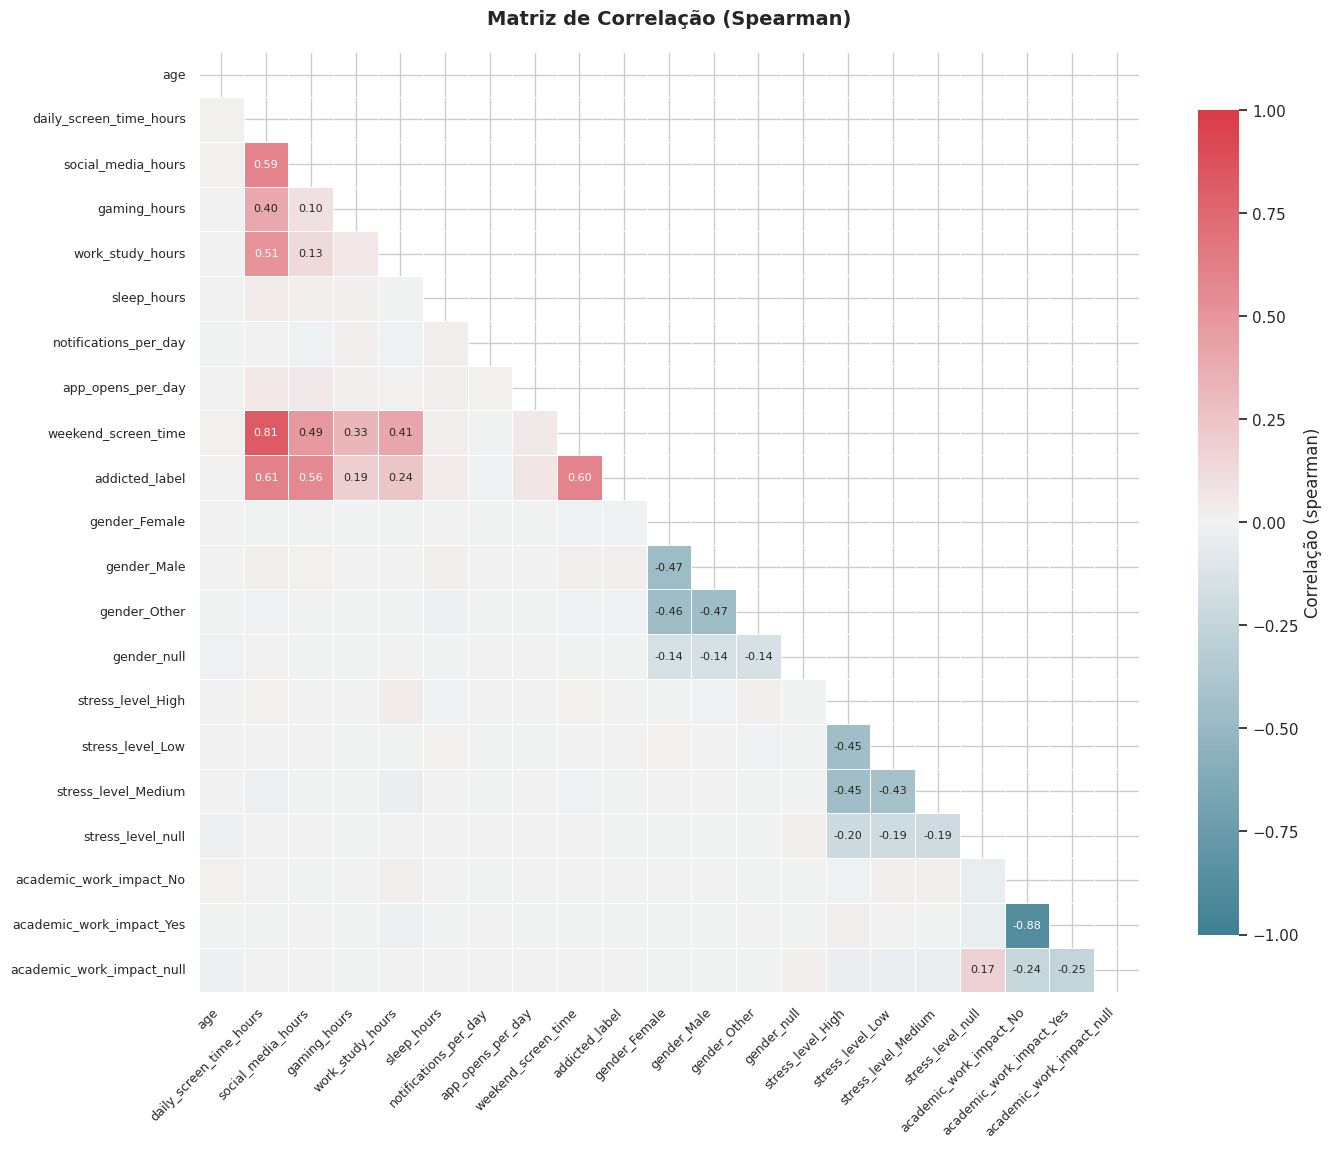

In [80]:
# Se quiser apenas o heatmap sem filtrar
fig = plot_correlation_heatmap(
    df_encoded.select(cs.numeric() - cs.by_name("id"))
)

Notebook to basic exploratory analisys automatically.
I use Polars to improve performance.

I used processes that are being applied to all columns in order to enable the following processes:
- Analyze columns with high cardinality.
- Remove unwanted columns and columns with high cardinality.
- Correct encoding of columns.
- Display and plot correlation.
- Convert String columns to numeric.

Lets'go!!! 

In [81]:
from sklearn.model_selection import KFold

In [82]:
k = 5 
kf = KFold(n_splits=k, shuffle=True, random_state=42)

In [83]:
df_encoded

id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label,gender_Female,gender_Male,gender_Other,gender_null,stress_level_High,stress_level_Low,stress_level_Medium,stress_level_null,academic_work_impact_No,academic_work_impact_Yes,academic_work_impact_null
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,i64,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8
0,24.0,null,1.83,1.59,2.11,7.46,122.0,38.0,8.63,"""Male""","""Medium""","""No""",1,0,1,0,0,0,0,1,0,1,0,0
1,19.0,5.97,1.08,null,3.03,8.22,76.0,19.0,null,"""Female""","""Medium""","""No""",0,1,0,0,0,0,0,1,0,1,0,0
2,18.0,5.09,null,null,null,6.25,134.0,60.0,7.47,"""Female""","""Low""","""Yes""",0,1,0,0,0,0,1,0,0,0,1,0
3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,"""Other""","""Low""",null,1,0,0,1,0,0,1,0,0,0,0,1
4,26.0,11.2,1.87,2.81,1.95,5.25,null,null,13.39,"""Female""","""Medium""","""No""",1,1,0,0,0,0,0,1,0,1,0,0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
691364,22.0,10.78,3.25,1.57,1.65,7.71,86.0,94.0,12.89,"""Male""",null,"""No""",1,0,1,0,0,0,0,0,1,1,0,0
691365,20.0,3.45,1.86,0.89,0.3,6.59,221.0,42.0,8.47,"""Female""","""High""","""No""",1,1,0,0,0,1,0,0,0,1,0,0
691366,null,null,null,null,2.06,6.16,null,86.0,7.79,"""Other""","""Medium""","""No""",1,0,0,1,0,0,0,1,0,1,0,0


In [84]:
x = df_encoded[:-1]

In [85]:
df_encoded[:,-1]

academic_work_impact_null
u8
0
0
0
1
0
…
0
0
0


In [86]:
y = df_encoded['addicted_label']

In [87]:
# Mover 'nome_coluna' para o início
colunas_ordenadas = [c for c in df_encoded.columns if c != "addicted_label"] + ["addicted_label"]

df_encoded = df_encoded.select(colunas_ordenadas)

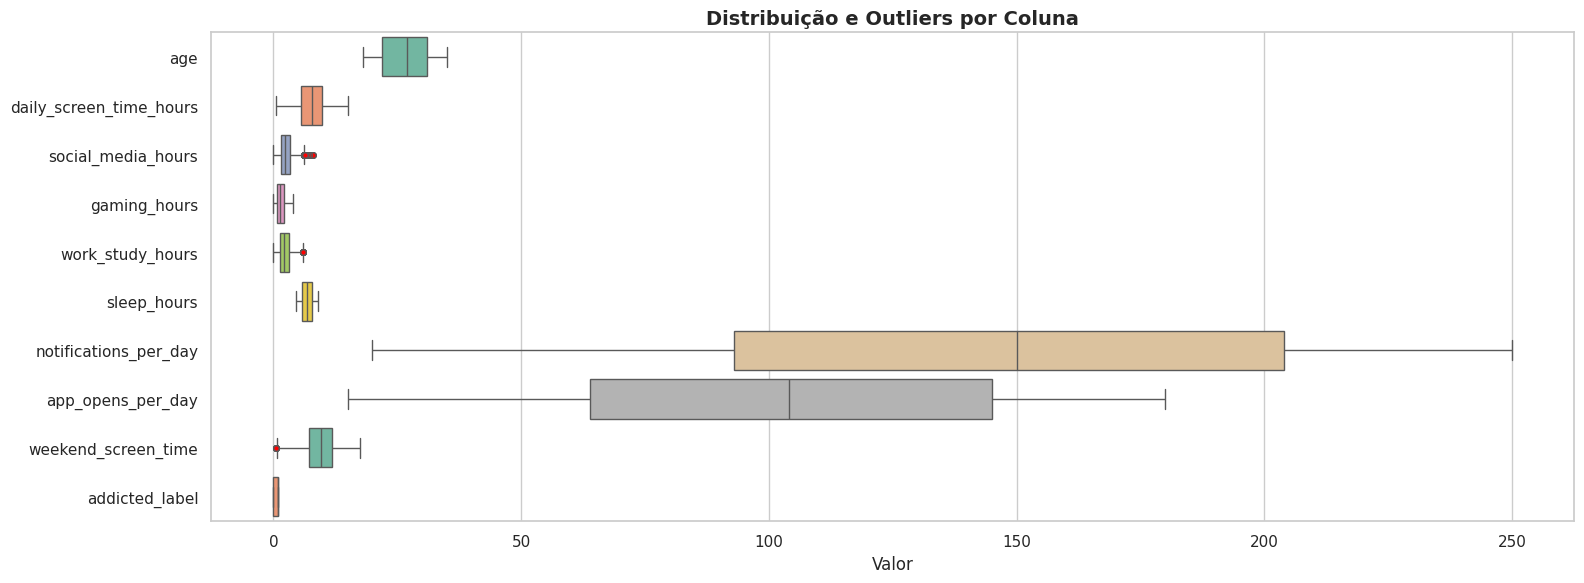

In [88]:

# Uso
boxplot_todas_colunas(df_encoded[:,1:])

In [89]:
temp = get_bool1(df_encoded, 'academic_work_impact', "Yes", "No")

In [90]:
temp_test = get_bool1(df_test_encoded, 'academic_work_impact', "Yes", "No")

In [91]:
print(type(temp))          # deve ser DataFrame
print(type(df_encoded))    # deve ser DataFrame

<class 'polars.series.series.Series'>
<class 'polars.dataframe.frame.DataFrame'>


In [92]:
temp.value_counts()

academic_work_impact,count
str,u32
"""1""",330566
null,44224
"""0""",316579


In [93]:
df_encoded.filter(pl.col("academic_work_impact").is_null())

id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,gender_Female,gender_Male,gender_Other,gender_null,stress_level_High,stress_level_Low,stress_level_Medium,stress_level_null,academic_work_impact_No,academic_work_impact_Yes,academic_work_impact_null,addicted_label
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,i64
3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,"""Other""","""Low""",null,0,0,1,0,0,1,0,0,0,0,1,1
9,20.0,8.74,1.4,2.43,2.11,8.57,null,109.0,10.68,"""Other""","""High""",null,0,0,1,0,1,0,0,0,0,0,1,1
25,27.0,11.77,3.66,2.97,2.0,7.26,213.0,111.0,13.33,"""Male""","""High""",null,0,1,0,0,1,0,0,0,0,0,1,1
26,null,6.68,1.89,1.61,2.24,5.47,194.0,103.0,7.54,"""Male""","""High""",null,0,1,0,0,1,0,0,0,0,0,1,1
36,19.0,4.92,0.67,2.36,1.49,null,236.0,118.0,8.77,"""Other""","""Medium""",null,0,0,1,0,0,0,1,0,0,0,1,0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
691311,30.0,8.98,2.64,2.21,3.45,7.44,183.0,157.0,10.65,"""Male""","""High""",null,0,1,0,0,1,0,0,0,0,0,1,1
691322,19.0,null,2.36,null,4.29,null,167.0,74.0,13.45,"""Female""","""Medium""",null,1,0,0,0,0,0,1,0,0,0,1,1
691331,26.0,5.97,2.71,2.0,0.9,null,220.0,75.0,5.93,"""Male""","""Medium""",null,0,1,0,0,0,0,1,0,0,0,1,0


In [94]:
temp = temp.to_frame()

In [95]:
temp

academic_work_impact
str
"""0"""
"""0"""
"""1"""
null
"""0"""
…
"""0"""
"""0"""
"""0"""


In [96]:
pl.col("academic_work_impact").is_null()

<Expr ['col("academic_work_impact").is…'] at 0x7B98330058B0>

In [97]:
# temp.filter(pl.col("academic_work_impact").is_null())

In [98]:
type(temp)

polars.dataframe.frame.DataFrame

In [99]:
type(df_encoded)

polars.dataframe.frame.DataFrame

In [100]:
temp

academic_work_impact
str
"""0"""
"""0"""
"""1"""
null
"""0"""
…
"""0"""
"""0"""
"""0"""


In [101]:
def fill_cols(df: pl.DataFrame, colunas: list[str]) -> pl.DataFrame:
    """
    Preenche nulos nas colunas especificadas:
    - Numéricas: mediana
    - Texto/categóricas: moda (valor mais frequente)
    """
    colunas_inexistentes = [c for c in colunas if c not in df.columns]
    if colunas_inexistentes:
        raise ValueError(f"Colunas não encontradas: {colunas_inexistentes}")
    
    expressoes = []
    for c in colunas:
        if df[c].dtype.is_numeric():
            expressoes.append(pl.col(c).fill_null(pl.col(c).median()))
        else:
            expressoes.append(
                pl.col(c).fill_null(pl.col(c).drop_nulls().mode().first())
            )
    
    return df.with_columns(expressoes)


In [102]:
df_encoded.columns

['id',
 'age',
 'daily_screen_time_hours',
 'social_media_hours',
 'gaming_hours',
 'work_study_hours',
 'sleep_hours',
 'notifications_per_day',
 'app_opens_per_day',
 'weekend_screen_time',
 'gender',
 'stress_level',
 'academic_work_impact',
 'gender_Female',
 'gender_Male',
 'gender_Other',
 'gender_null',
 'stress_level_High',
 'stress_level_Low',
 'stress_level_Medium',
 'stress_level_null',
 'academic_work_impact_No',
 'academic_work_impact_Yes',
 'academic_work_impact_null',
 'addicted_label']

In [103]:
type(df_encoded.columns)

list

In [104]:
# ✅ Preencher várias colunas
df_preenchido = fill_cols(df_encoded, df_encoded.columns)
df_preenchido

id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,gender_Female,gender_Male,gender_Other,gender_null,stress_level_High,stress_level_Low,stress_level_Medium,stress_level_null,academic_work_impact_No,academic_work_impact_Yes,academic_work_impact_null,addicted_label
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0.0,24.0,7.77,1.83,1.59,2.11,7.46,122.0,38.0,8.63,"""Male""","""Medium""","""No""",0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
1.0,19.0,5.97,1.08,1.33,3.03,8.22,76.0,19.0,9.58,"""Female""","""Medium""","""No""",1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
2.0,18.0,5.09,2.31,1.33,2.2,6.25,134.0,60.0,7.47,"""Female""","""Low""","""Yes""",1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
3.0,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,"""Other""","""Low""","""Yes""",0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0
4.0,26.0,11.2,1.87,2.81,1.95,5.25,150.0,104.0,13.39,"""Female""","""Medium""","""No""",1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
691364.0,22.0,10.78,3.25,1.57,1.65,7.71,86.0,94.0,12.89,"""Male""","""High""","""No""",0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
691365.0,20.0,3.45,1.86,0.89,0.3,6.59,221.0,42.0,8.47,"""Female""","""High""","""No""",1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
691366.0,27.0,7.77,2.31,1.33,2.06,6.16,150.0,86.0,7.79,"""Other""","""Medium""","""No""",0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0


In [105]:
df_preenchido_test = fill_cols(df_test_encoded, df_test_encoded.columns)
df_preenchido_test

id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,gender_Female,gender_Male,gender_Other,gender_null,stress_level_High,stress_level_Low,stress_level_Medium,stress_level_null,academic_work_impact_No,academic_work_impact_Yes,academic_work_impact_null
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
691369.0,30.0,9.34,2.32,0.77,4.09,7.15,153.0,16.0,9.58,"""Other""","""Medium""","""Yes""",0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
691370.0,27.0,7.77,1.91,1.33,1.2,8.67,239.0,148.0,10.68,"""Female""","""High""","""No""",1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
691371.0,26.0,8.48,3.64,1.33,3.39,7.47,106.0,123.0,9.58,"""Male""","""High""","""No""",0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
691372.0,20.0,8.37,2.99,1.69,2.53,5.45,178.0,55.0,9.88,"""Male""","""High""","""Yes""",0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
691373.0,25.0,8.25,4.02,1.21,2.32,8.46,63.0,86.0,10.72,"""Male""","""Low""","""No""",0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
987666.0,25.0,11.76,5.15,1.94,2.75,8.24,237.0,127.0,14.1,"""Male""","""High""","""Yes""",0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
987667.0,28.0,7.67,2.7,1.55,2.95,5.54,187.0,121.0,8.25,"""Male""","""Low""","""Yes""",0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
987668.0,33.0,5.27,1.84,0.2,2.44,8.29,96.0,73.0,6.57,"""Female""","""High""","""No""",1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [106]:
df_preenchido.null_count()

id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,gender_Female,gender_Male,gender_Other,gender_null,stress_level_High,stress_level_Low,stress_level_Medium,stress_level_null,academic_work_impact_No,academic_work_impact_Yes,academic_work_impact_null,addicted_label
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [107]:
df_preenchido_test.null_count()

id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,gender_Female,gender_Male,gender_Other,gender_null,stress_level_High,stress_level_Low,stress_level_Medium,stress_level_null,academic_work_impact_No,academic_work_impact_Yes,academic_work_impact_null
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [108]:
# df_encoded = df_preenchido.with_columns(
#     pl.col("genero").to_dummies()
# )

In [109]:
df_preenchido['academic_work_impact']

academic_work_impact
str
"""No"""
"""No"""
"""Yes"""
"""Yes"""
"""No"""
…
"""No"""
"""No"""
"""No"""


In [110]:
# Lista de colunas que não são string
column_temp = [
    col for col in df_preenchido.columns
    #pl.Utf8 it's not string in rust
    if df_preenchido[col].dtype != pl.Utf8
]

print("Colunas que não são string:", column_temp)

Colunas que não são string: ['id', 'age', 'daily_screen_time_hours', 'social_media_hours', 'gaming_hours', 'work_study_hours', 'sleep_hours', 'notifications_per_day', 'app_opens_per_day', 'weekend_screen_time', 'gender_Female', 'gender_Male', 'gender_Other', 'gender_null', 'stress_level_High', 'stress_level_Low', 'stress_level_Medium', 'stress_level_null', 'academic_work_impact_No', 'academic_work_impact_Yes', 'academic_work_impact_null', 'addicted_label']


In [111]:
type(column_temp)

list

In [112]:
df_preenchido[ column_temp[1:len(column_temp)] ]

age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender_Female,gender_Male,gender_Other,gender_null,stress_level_High,stress_level_Low,stress_level_Medium,stress_level_null,academic_work_impact_No,academic_work_impact_Yes,academic_work_impact_null,addicted_label
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
24.0,7.77,1.83,1.59,2.11,7.46,122.0,38.0,8.63,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
19.0,5.97,1.08,1.33,3.03,8.22,76.0,19.0,9.58,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
18.0,5.09,2.31,1.33,2.2,6.25,134.0,60.0,7.47,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0
26.0,11.2,1.87,2.81,1.95,5.25,150.0,104.0,13.39,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
22.0,10.78,3.25,1.57,1.65,7.71,86.0,94.0,12.89,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
20.0,3.45,1.86,0.89,0.3,6.59,221.0,42.0,8.47,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
27.0,7.77,2.31,1.33,2.06,6.16,150.0,86.0,7.79,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0


In [113]:
# X = X[ X.dtypes != 'String' ]

In [114]:
from sklearn.model_selection import cross_val_score 

In [115]:
y

addicted_label
i64
1
0
0
1
1
…
1
1
1


In [116]:
column_temp

['id',
 'age',
 'daily_screen_time_hours',
 'social_media_hours',
 'gaming_hours',
 'work_study_hours',
 'sleep_hours',
 'notifications_per_day',
 'app_opens_per_day',
 'weekend_screen_time',
 'gender_Female',
 'gender_Male',
 'gender_Other',
 'gender_null',
 'stress_level_High',
 'stress_level_Low',
 'stress_level_Medium',
 'stress_level_null',
 'academic_work_impact_No',
 'academic_work_impact_Yes',
 'academic_work_impact_null',
 'addicted_label']

In [117]:
X = df_preenchido[ column_temp[1:len(column_temp)-1] ]

In [118]:
X.shape

(691369, 20)

In [119]:
from sklearn.linear_model import LogisticRegression  # ← troque aqui

In [120]:
model = LogisticRegression(max_iter=1000)

In [121]:
scores = cross_val_score(model, X, y, cv=kf, scoring='roc_auc')

In [122]:
print("AUC scores:", scores)
print(f"AUC scores: {scores}")
print(f"Mean AUC: {scores.mean():.4f} ± {scores.std():.4f}")

AUC scores: [0.91153989 0.91317186 0.91124033 0.90999793 0.91150092]
AUC scores: [0.91153989 0.91317186 0.91124033 0.90999793 0.91150092]
Mean AUC: 0.9115 ± 0.0010


In [123]:
df_preenchido_test

id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,gender_Female,gender_Male,gender_Other,gender_null,stress_level_High,stress_level_Low,stress_level_Medium,stress_level_null,academic_work_impact_No,academic_work_impact_Yes,academic_work_impact_null
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
691369.0,30.0,9.34,2.32,0.77,4.09,7.15,153.0,16.0,9.58,"""Other""","""Medium""","""Yes""",0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
691370.0,27.0,7.77,1.91,1.33,1.2,8.67,239.0,148.0,10.68,"""Female""","""High""","""No""",1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
691371.0,26.0,8.48,3.64,1.33,3.39,7.47,106.0,123.0,9.58,"""Male""","""High""","""No""",0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
691372.0,20.0,8.37,2.99,1.69,2.53,5.45,178.0,55.0,9.88,"""Male""","""High""","""Yes""",0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
691373.0,25.0,8.25,4.02,1.21,2.32,8.46,63.0,86.0,10.72,"""Male""","""Low""","""No""",0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
987666.0,25.0,11.76,5.15,1.94,2.75,8.24,237.0,127.0,14.1,"""Male""","""High""","""Yes""",0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
987667.0,28.0,7.67,2.7,1.55,2.95,5.54,187.0,121.0,8.25,"""Male""","""Low""","""Yes""",0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
987668.0,33.0,5.27,1.84,0.2,2.44,8.29,96.0,73.0,6.57,"""Female""","""High""","""No""",1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [124]:
# ✅ Previsão no TESTE (não tem y → não calcula AUC, só prevê)
X_test = df_preenchido_test.to_numpy()  # base de teste já encodada

# Probabilidades da classe positiva (para AUC/submissão)

In [125]:
df_preenchido_test.dtypes

[Float64,
 Float64,
 Float64,
 Float64,
 Float64,
 Float64,
 Float64,
 Float64,
 Float64,
 Float64,
 String,
 String,
 String,
 Float64,
 Float64,
 Float64,
 Float64,
 Float64,
 Float64,
 Float64,
 Float64,
 Float64,
 Float64,
 Float64]

In [126]:
X.columns

['age',
 'daily_screen_time_hours',
 'social_media_hours',
 'gaming_hours',
 'work_study_hours',
 'sleep_hours',
 'notifications_per_day',
 'app_opens_per_day',
 'weekend_screen_time',
 'gender_Female',
 'gender_Male',
 'gender_Other',
 'gender_null',
 'stress_level_High',
 'stress_level_Low',
 'stress_level_Medium',
 'stress_level_null',
 'academic_work_impact_No',
 'academic_work_impact_Yes',
 'academic_work_impact_null']

In [127]:
df_preenchido_test[X.columns]

age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender_Female,gender_Male,gender_Other,gender_null,stress_level_High,stress_level_Low,stress_level_Medium,stress_level_null,academic_work_impact_No,academic_work_impact_Yes,academic_work_impact_null
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
30.0,9.34,2.32,0.77,4.09,7.15,153.0,16.0,9.58,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
27.0,7.77,1.91,1.33,1.2,8.67,239.0,148.0,10.68,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
26.0,8.48,3.64,1.33,3.39,7.47,106.0,123.0,9.58,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
20.0,8.37,2.99,1.69,2.53,5.45,178.0,55.0,9.88,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
25.0,8.25,4.02,1.21,2.32,8.46,63.0,86.0,10.72,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
25.0,11.76,5.15,1.94,2.75,8.24,237.0,127.0,14.1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
28.0,7.67,2.7,1.55,2.95,5.54,187.0,121.0,8.25,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
33.0,5.27,1.84,0.2,2.44,8.29,96.0,73.0,6.57,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [128]:
model.fit(X, y)

LogisticRegression(max_iter=1000)

In [129]:
type(X_test)

numpy.ndarray

In [130]:
y_test_proba = model.predict_proba(df_preenchido_test[X.columns])[:, 1]

In [131]:
# df_preenchido_test[X.columns]

In [132]:
# Ou classes diretamente
y_test_pred = model.predict(df_preenchido_test[X.columns])

In [133]:
def submit(dataframe, submit):
    
    submission_final = pd.DataFrame({

        "id": dataframe['id'],

        "exam_score": submit

    })
    ## Submit notebooks to the challenge. Final
    submission_final.to_csv('submission.csv', index=False)
    print(" Arquivo submission.csv pronto ")

In [134]:
type(df_preenchido_test['id'])

polars.series.series.Series

In [135]:
submit(df_preenchido_test, y_test_pred)

 Arquivo submission.csv pronto 
